# Mushrooms classification

Proyecto desarrollado a partir del análisis de la base de datos de mushrooms disponible en Kaggle. Rescatado en: 
- UCI Machine Learning. (s. f.). Mushroom classification [Conjunto de datos]. Kaggle. Recuperado el 14 de octubre de 2026, de https://www.kaggle.com/datasets/uciml/mushroom-classification


## Carga de datos

In [ ]:
#!pip install pandas kagglehub
#!pip install matplotlib
#!pip install seaborn
#!pip install numpy
#!pip install scipy
#!pip install factor_analyzer
#!pip install --upgrade seaborn matplotlib numpy

   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ------------------- -------------------- 6.0/12.6 MB 30.7 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 37.5 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.3
    Uninstalling numpy-2.5.3:
      Successfully uninstalled numpy-2.5.3



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency

In [8]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/mushroom-classification")

print("Path to dataset files:", path)


c:\Users\diego\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\diego\.cache\kagglehub\datasets\uciml\mushroom-classification\versions\1


In [9]:
df = pd.read_csv("C:/Users/diego/.cache/kagglehub/datasets/uciml/mushroom-classification/versions/1/mushrooms.csv")

Notamos que el dataset está sin valores nulos, por lo que no requiere inputación ni decisiones de limpieza

## EDA

### Tablas

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

In [11]:
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


Tenemos clases relativamente balanceadas

In [12]:
df["class"].value_counts(normalize = True)

class
e    0.517971
p    0.482029
Name: proportion, dtype: float64

In [13]:
# 1. Diccionario para cambiar los nombres de las columnas 🏷️
columnas_esp = {
    'class': 'clase',
    'cap-shape': 'forma_sombrero',
    'cap-surface': 'superficie_sombrero',
    'cap-color': 'color_sombrero',
    'bruises': 'hematomas',
    'odor': 'olor',
    'gill-attachment': 'insercion_laminas',
    'gill-spacing': 'espaciado_laminas',
    'gill-size': 'tamano_laminas',
    'gill-color': 'color_laminas',
    'stalk-shape': 'forma_pie',
    'stalk-root': 'raiz_pie',
    'stalk-surface-above-ring': 'superficie_pie_sobre_anillo',
    'stalk-surface-below-ring': 'superficie_pie_bajo_anillo',
    'stalk-color-above-ring': 'color_pie_sobre_anillo',
    'stalk-color-below-ring': 'color_pie_bajo_anillo',
    'veil-type': 'tipo_velo',
    'veil-color': 'color_velo',
    'ring-number': 'numero_anillos',
    'ring-type': 'tipo_anillo',
    'spore-print-color': 'color_esporas',
    'population': 'poblacion',
    'habitat': 'habitat'
}

# 2. Diccionario con la traducción de todos los valores categóricos 🔤
traducciones_valores = {
    'clase': {'e': 'comestible', 'p': 'venenoso'},
    'forma_sombrero': {'b': 'campana', 'c': 'conico', 'x': 'convexo', 'f': 'plano', 'k': 'nudoso', 's': 'hundido'},
    'superficie_sombrero': {'f': 'fibrosa', 'g': 'surcos', 'y': 'escamosa', 's': 'suave'},
    'color_sombrero': {'n': 'marron', 'b': 'fuelle', 'c': 'canela', 'g': 'gris', 'r': 'verde', 'p': 'rosa', 'u': 'morado', 'e': 'rojo', 'w': 'blanco', 'y': 'amarillo'},
    'hematomas': {'t': 'si', 'f': 'no'},
    'olor': {'a': 'almendra', 'l': 'anís', 'c': 'creosota', 'y': 'pescado', 'f': 'fétido', 'm': 'moho', 'n': 'ninguno', 'p': 'picante', 's': 'picante_fuerte'},
    'insercion_laminas': {'a': 'adherida', 'd': 'descendente', 'f': 'libre', 'n': 'muesca'},
    'espaciado_laminas': {'c': 'cercano', 'w': 'disperso', 'd': 'distante'},
    'tamano_laminas': {'b': 'ancho', 'n': 'estrecho'},
    'color_laminas': {'k': 'negro', 'n': 'marron', 'b': 'fuelle', 'h': 'chocolate', 'g': 'gris', 'r': 'verde', 'o': 'naranja', 'p': 'rosa', 'u': 'morado', 'e': 'rojo', 'w': 'blanco', 'y': 'amarillo'},
    'forma_pie': {'e': 'agrandado', 't': 'conico'},
    'raiz_pie': {'b': 'bulbosa', 'c': 'casa', 'u': 'copa', 'e': 'igual', 'z': 'raíz', 'r': 'enraizada', '?': 'desconocido'},
    'superficie_pie_sobre_anillo': {'f': 'fibrosa', 'y': 'escamosa', 'k': 'sedosa', 's': 'suave'},
    'superficie_pie_bajo_anillo': {'f': 'fibrosa', 'y': 'escamosa', 'k': 'sedosa', 's': 'suave'},
    'color_pie_sobre_anillo': {'n': 'marron', 'b': 'fuelle', 'c': 'canela', 'g': 'gris', 'o': 'naranja', 'p': 'rosa', 'e': 'rojo', 'w': 'blanco', 'y': 'amarillo'},
    'color_pie_bajo_anillo': {'n': 'marron', 'b': 'fuelle', 'c': 'canela', 'g': 'gris', 'o': 'naranja', 'p': 'rosa', 'e': 'rojo', 'w': 'blanco', 'y': 'amarillo'},
    'tipo_velo': {'p': 'parcial', 'u': 'universal'},
    'color_velo': {'n': 'marron', 'o': 'naranja', 'w': 'blanco', 'y': 'amarillo'},
    'numero_anillos': {'n': 'ninguno', 'o': 'uno', 't': 'dos'},
    'tipo_anillo': {'c': 'telaraña', 'e': 'evanescente', 'f': 'flamante', 'l': 'grande', 'n': 'ninguno', 'p': 'colgante', 's': 'envainante', 'z': 'zona'},
    'color_esporas': {'k': 'negro', 'n': 'marron', 'b': 'fuelle', 'h': 'chocolate', 'r': 'verde', 'o': 'naranja', 'u': 'morado', 'w': 'blanco', 'y': 'amarillo'},
    'poblacion': {'a': 'abundante', 'c': 'agrupada', 'n': 'numerosa', 's': 'dispersa', 'v': 'varias', 'y': 'solitaria'},
    'habitat': {'g': 'pastizal', 'l': 'hojarasca', 'm': 'prado', 'p': 'senderos', 'u': 'urbano', 'w': 'residuos', 'd': 'bosque'}
}

In [14]:
df = df.rename(columns = columnas_esp)
df = df.replace(traducciones_valores)

In [15]:
for i in df.columns:
    print(df[i].value_counts())

clase
comestible    4208
venenoso      3916
Name: count, dtype: int64
forma_sombrero
convexo    3656
plano      3152
nudoso      828
campana     452
hundido      32
conico        4
Name: count, dtype: int64
superficie_sombrero
escamosa    3244
suave       2556
fibrosa     2320
surcos         4
Name: count, dtype: int64
color_sombrero
marron      2284
gris        1840
rojo        1500
amarillo    1072
blanco      1040
fuelle       168
rosa         144
canela        44
morado        16
verde         16
Name: count, dtype: int64
hematomas
no    4748
si    3376
Name: count, dtype: int64
olor
ninguno           3528
fétido            2160
pescado            576
picante_fuerte     576
almendra           400
anís               400
picante            256
creosota           192
moho                36
Name: count, dtype: int64
insercion_laminas
libre       7914
adherida     210
Name: count, dtype: int64
espaciado_laminas
cercano     6812
disperso    1312
Name: count, dtype: int64
tamano_laminas
a

In [16]:
for i in df.columns:
    print(df[i].value_counts(normalize=True))

clase
comestible    0.517971
venenoso      0.482029
Name: proportion, dtype: float64
forma_sombrero
convexo    0.450025
plano      0.387986
nudoso     0.101920
campana    0.055638
hundido    0.003939
conico     0.000492
Name: proportion, dtype: float64
superficie_sombrero
escamosa    0.399311
suave       0.314623
fibrosa     0.285574
surcos      0.000492
Name: proportion, dtype: float64
color_sombrero
marron      0.281142
gris        0.226489
rojo        0.184638
amarillo    0.131955
blanco      0.128016
fuelle      0.020679
rosa        0.017725
canela      0.005416
morado      0.001969
verde       0.001969
Name: proportion, dtype: float64
hematomas
no    0.584441
si    0.415559
Name: proportion, dtype: float64
olor
ninguno           0.434269
fétido            0.265879
pescado           0.070901
picante_fuerte    0.070901
almendra          0.049237
anís              0.049237
picante           0.031512
creosota          0.023634
moho              0.004431
Name: proportion, dtype: float6

### Gráficos univariados

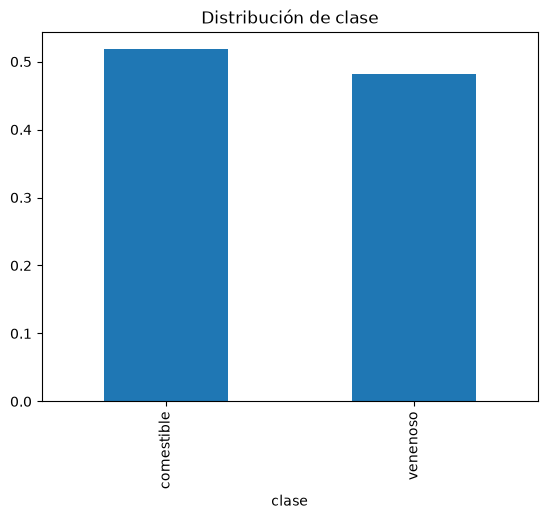

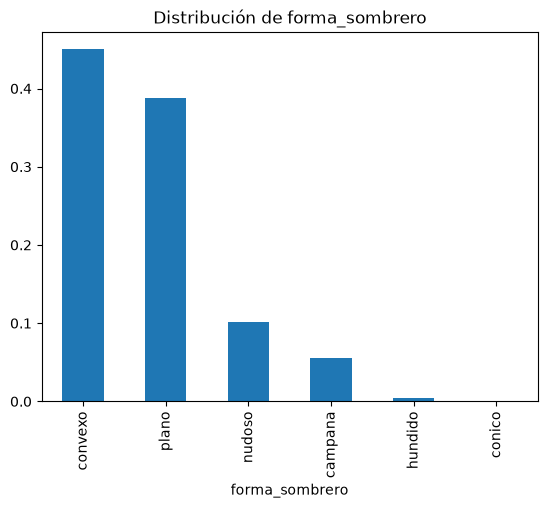

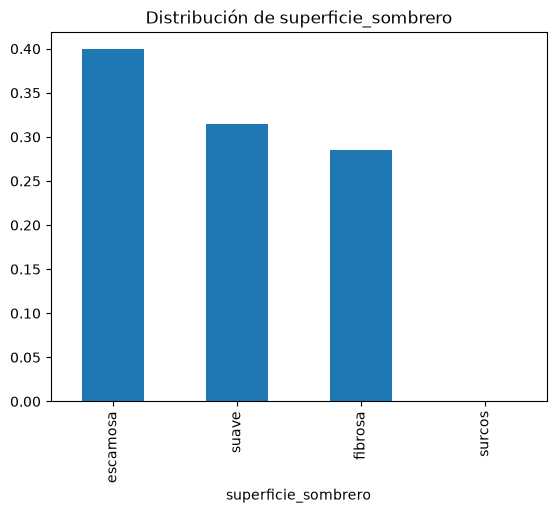

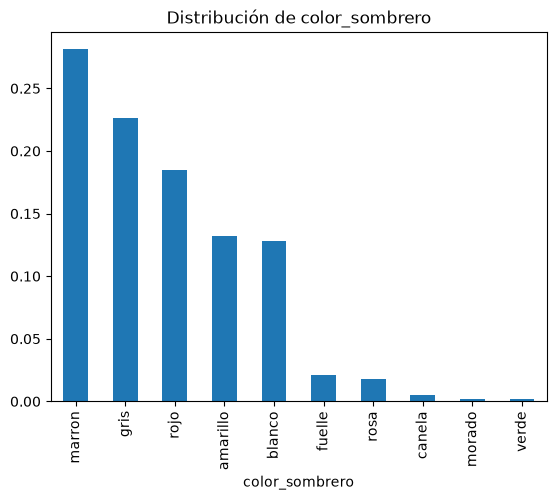

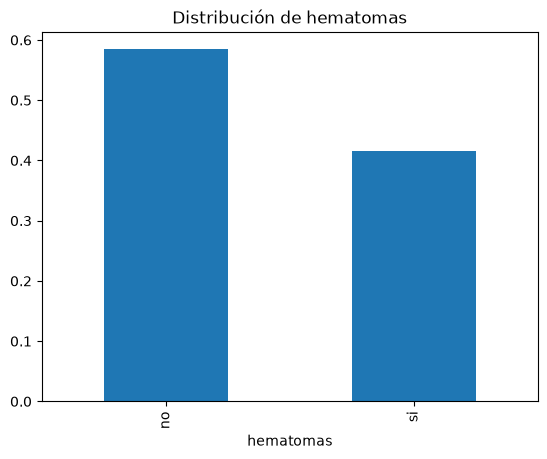

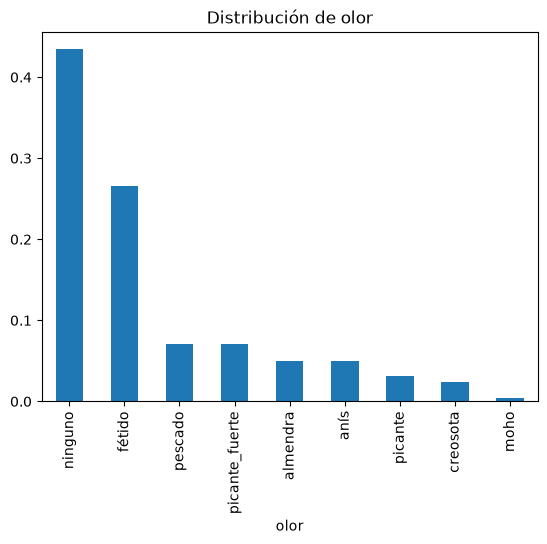

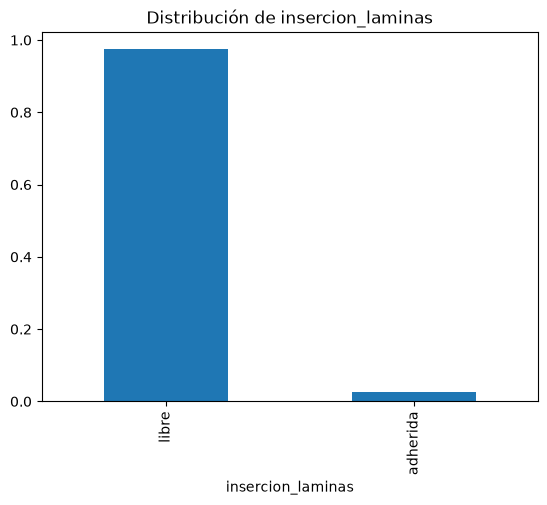

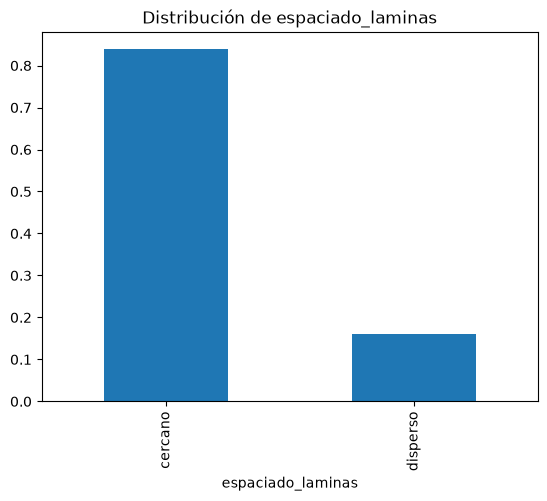

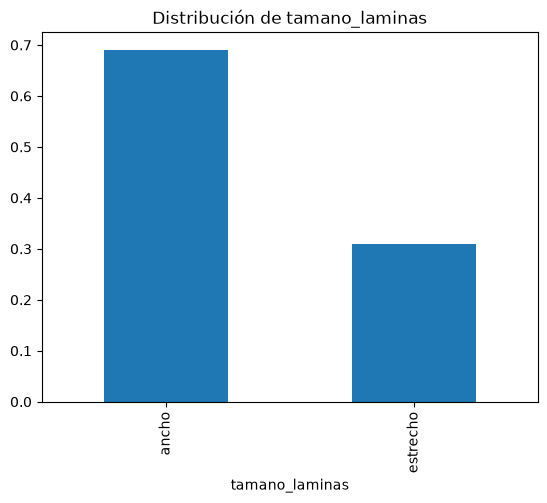

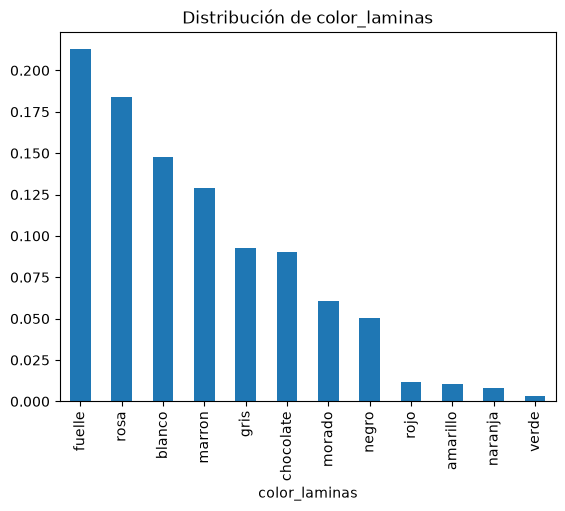

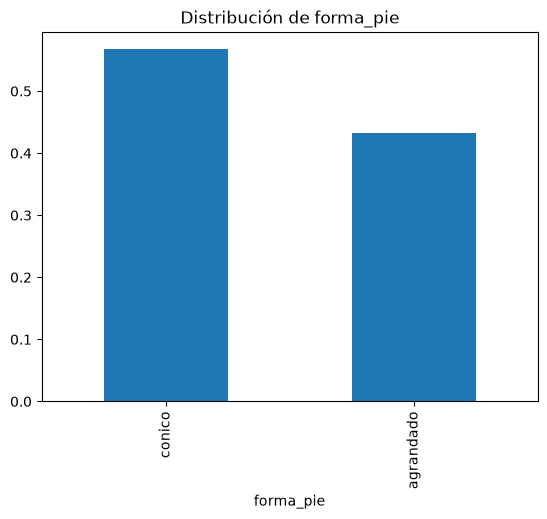

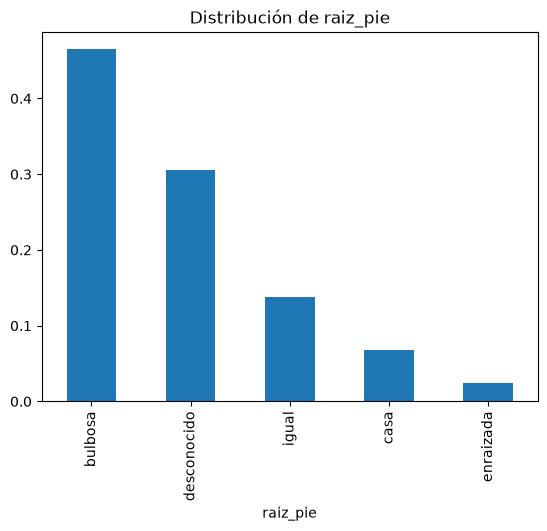

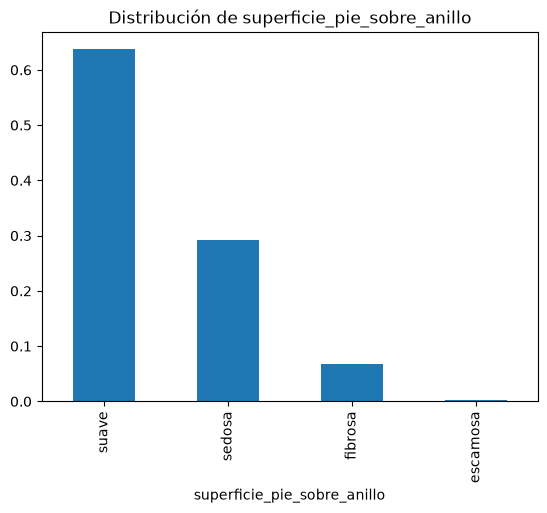

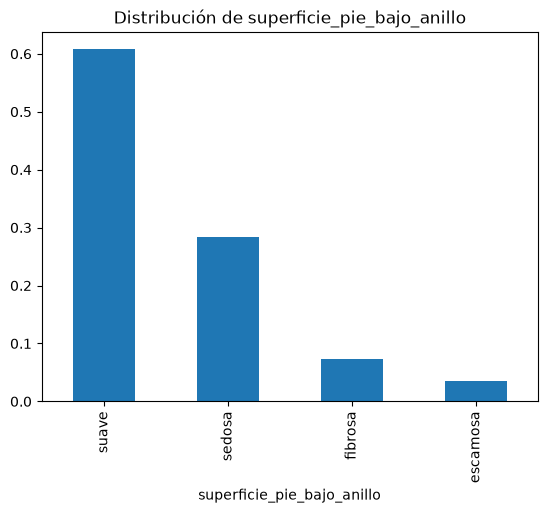

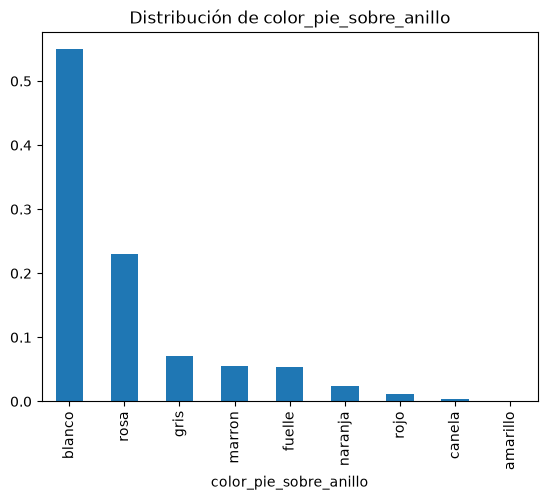

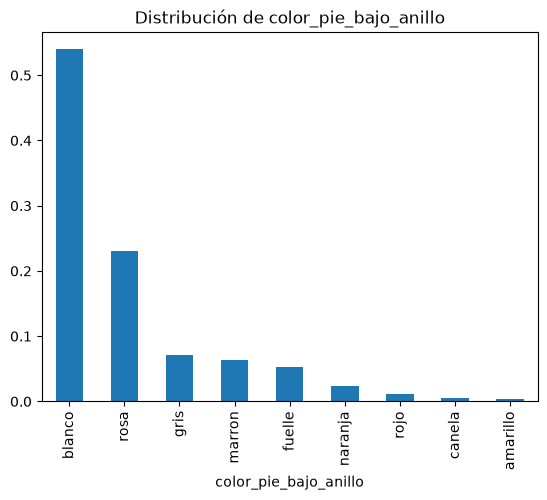

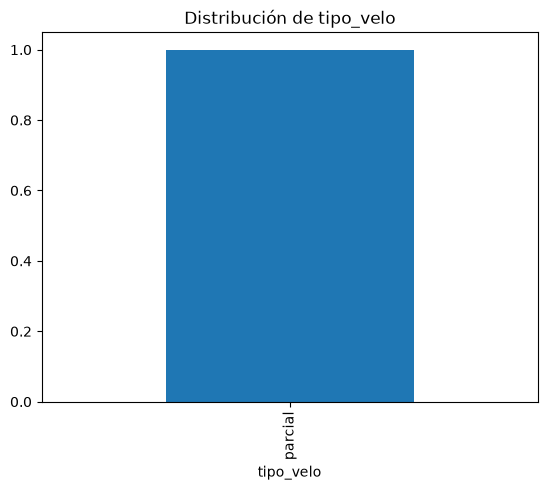

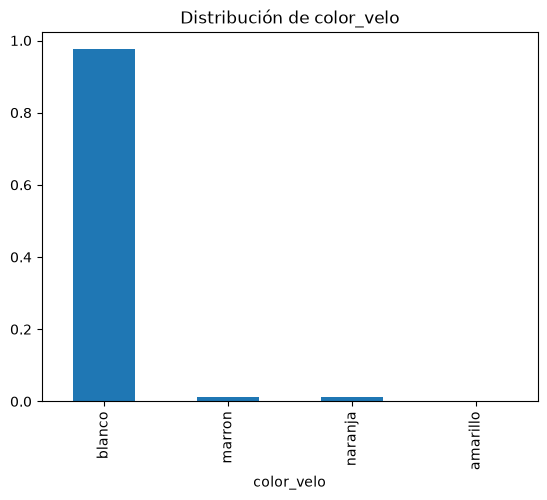

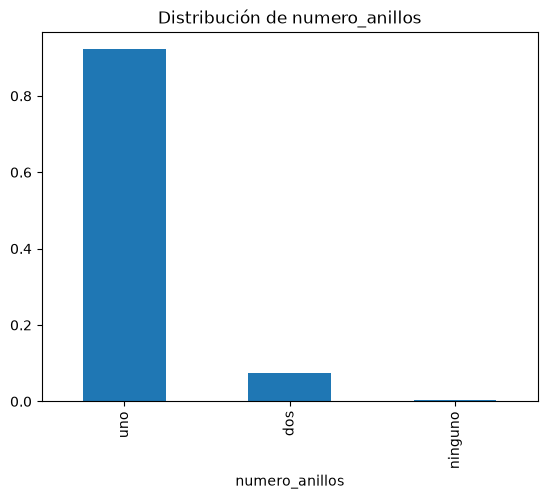

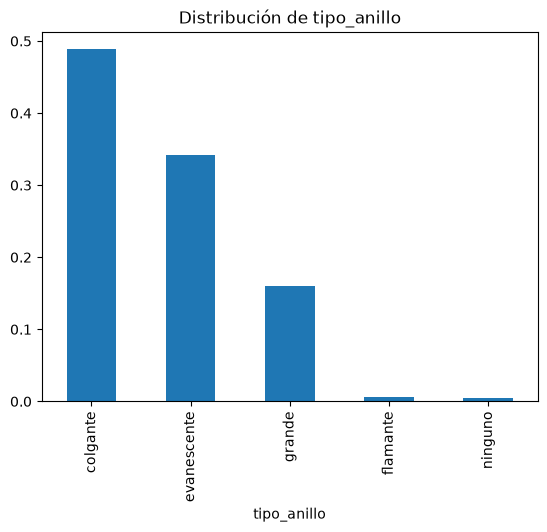

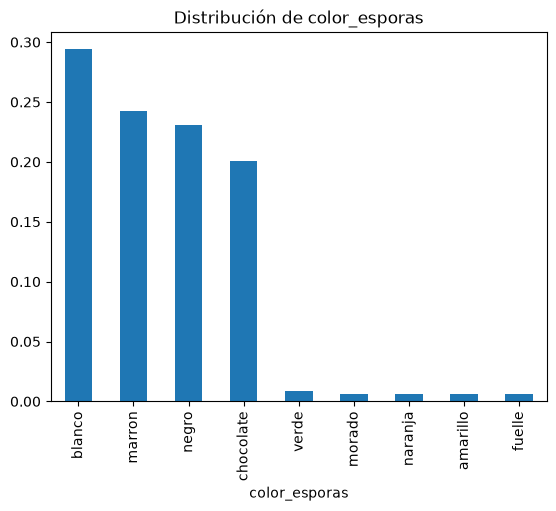

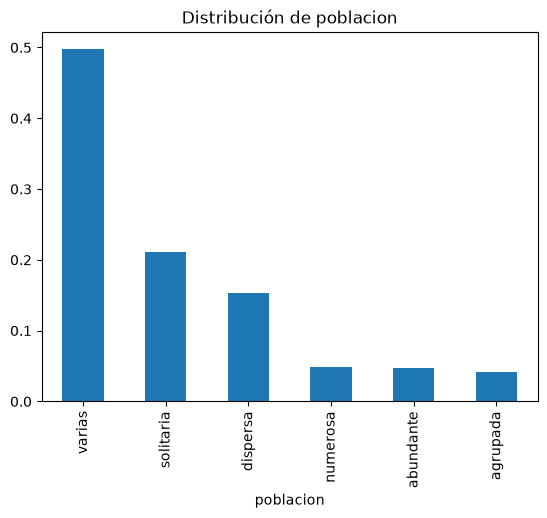

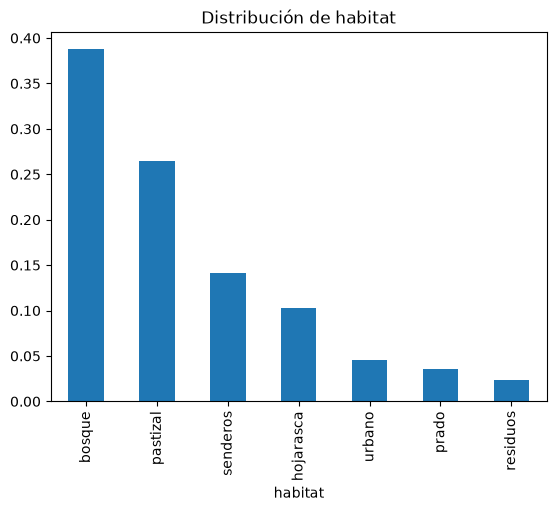

In [17]:
for i in df.columns:
    df[i].value_counts(normalize=True).plot(kind='bar')
    plt.title(f'Distribución de {i}')
    plt.show()

### Gráficos Bivariados

In [18]:
df.columns

Index(['clase', 'forma_sombrero', 'superficie_sombrero', 'color_sombrero',
       'hematomas', 'olor', 'insercion_laminas', 'espaciado_laminas',
       'tamano_laminas', 'color_laminas', 'forma_pie', 'raiz_pie',
       'superficie_pie_sobre_anillo', 'superficie_pie_bajo_anillo',
       'color_pie_sobre_anillo', 'color_pie_bajo_anillo', 'tipo_velo',
       'color_velo', 'numero_anillos', 'tipo_anillo', 'color_esporas',
       'poblacion', 'habitat'],
      dtype='str')

In [19]:
df[["habitat", "clase"]].value_counts()

habitat    clase     
bosque     comestible    1880
pastizal   comestible    1408
bosque     venenoso      1268
senderos   venenoso      1008
pastizal   venenoso       740
hojarasca  venenoso       592
urbano     venenoso       272
prado      comestible     256
hojarasca  comestible     240
residuos   comestible     192
senderos   comestible     136
urbano     comestible      96
prado      venenoso        36
Name: count, dtype: int64

In [20]:
df[["olor","clase"]].value_counts()

olor            clase     
ninguno         comestible    3408
fétido          venenoso      2160
pescado         venenoso       576
picante_fuerte  venenoso       576
almendra        comestible     400
anís            comestible     400
picante         venenoso       256
creosota        venenoso       192
ninguno         venenoso       120
moho            venenoso        36
Name: count, dtype: int64

In [21]:
tabla = pd.crosstab(df["color_esporas"], df['clase'], normalize='index')
print(tabla)

clase          comestible  venenoso
color_esporas                      
amarillo         1.000000  0.000000
blanco           0.241206  0.758794
chocolate        0.029412  0.970588
fuelle           1.000000  0.000000
marron           0.886179  0.113821
morado           1.000000  0.000000
naranja          1.000000  0.000000
negro            0.880342  0.119658
verde            0.000000  1.000000


Notamos que hay existencia de caracteristicas que clasifican directamente, lo que muestra que es posible realizar reglas para identificar si son venenosos o no

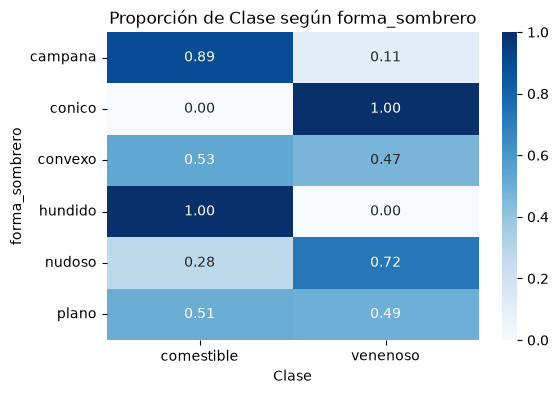

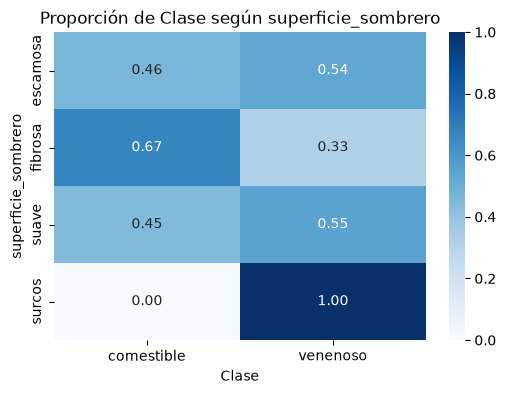

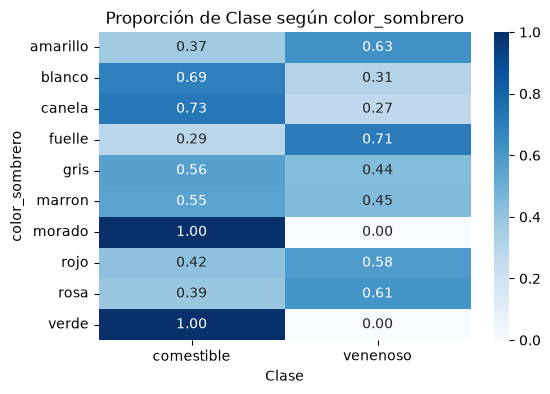

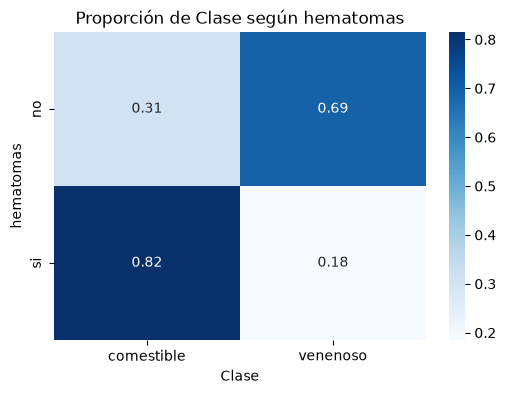

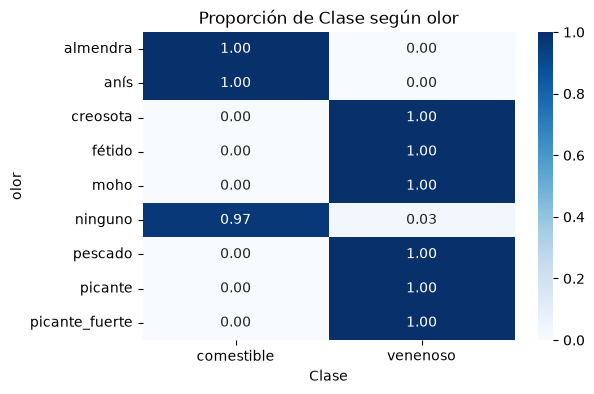

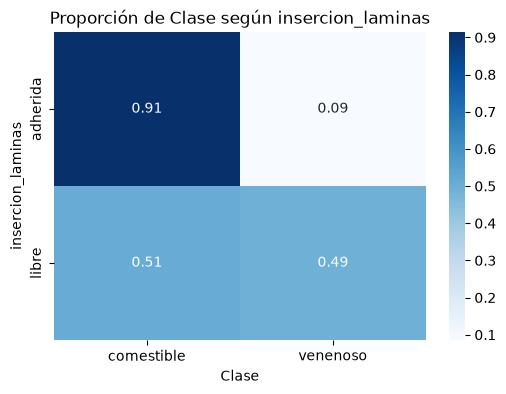

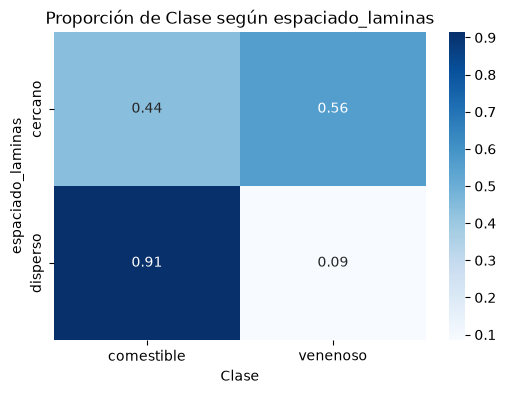

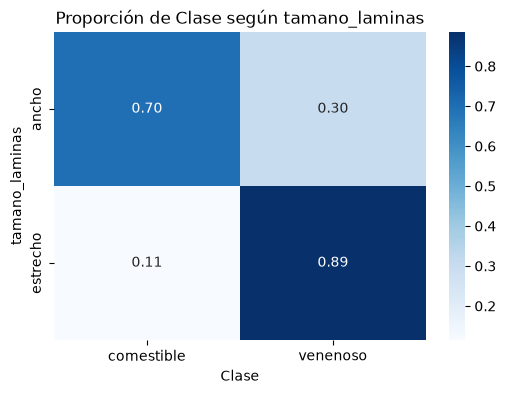

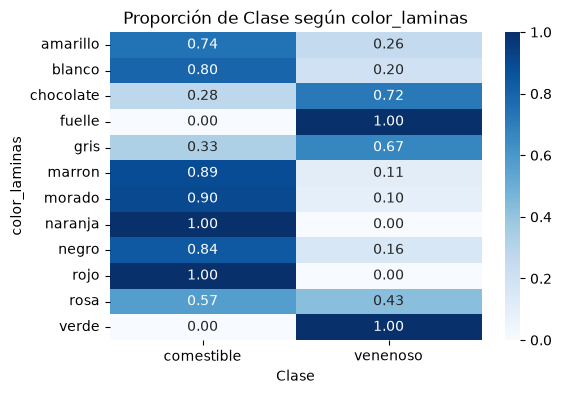

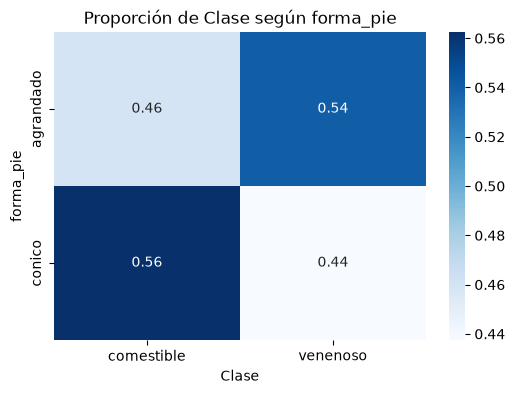

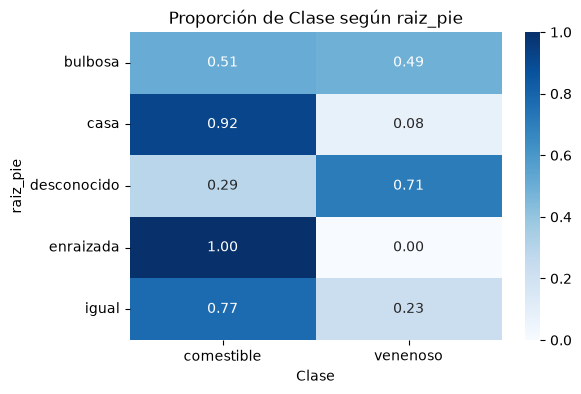

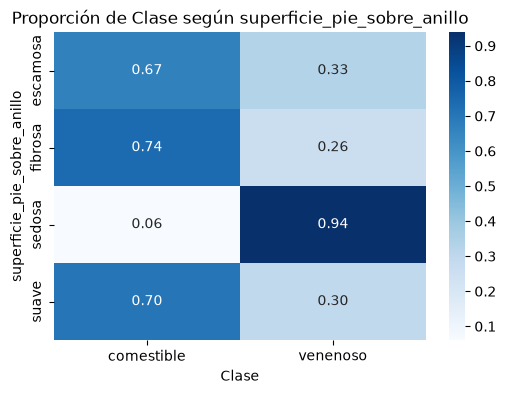

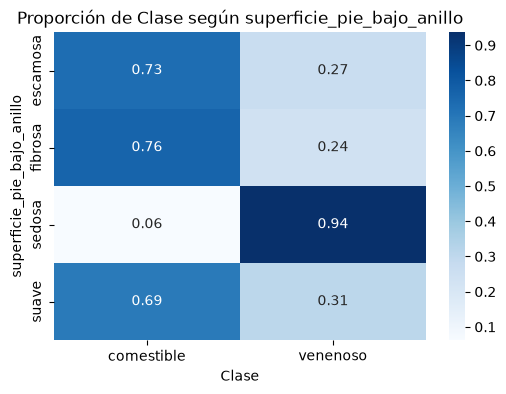

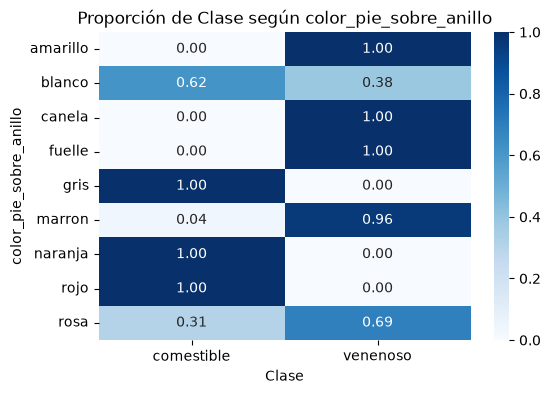

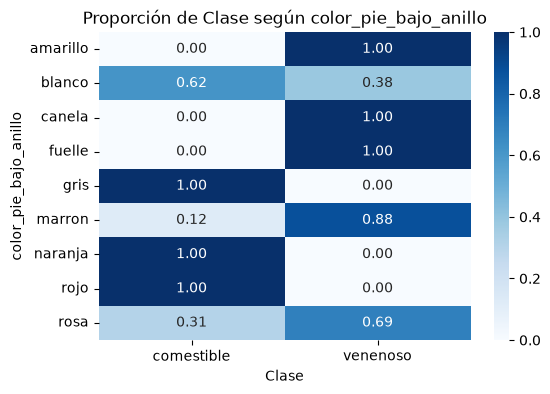

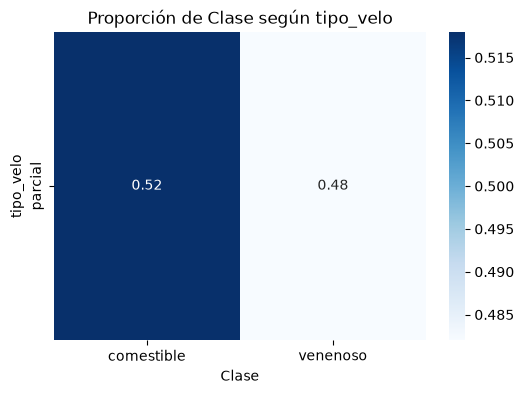

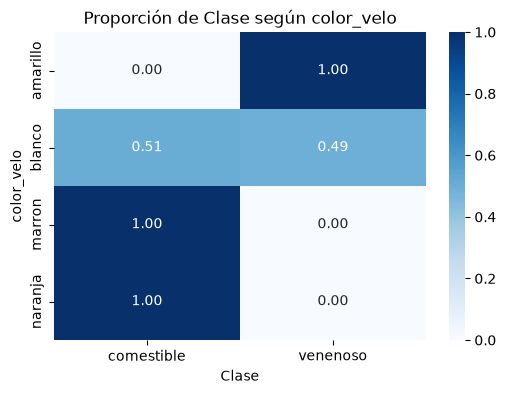

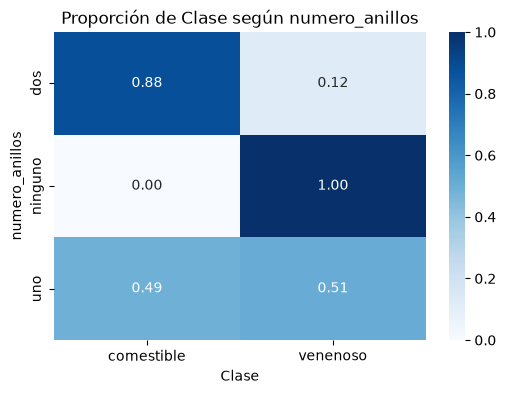

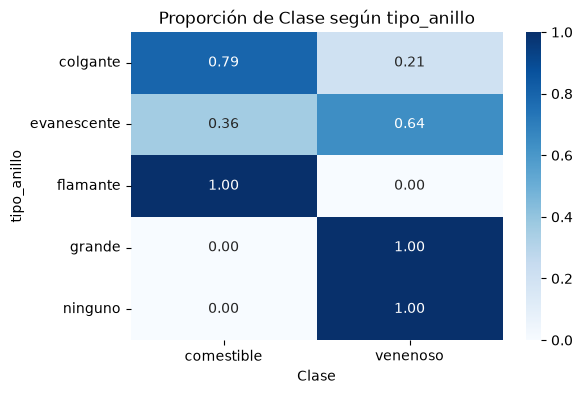

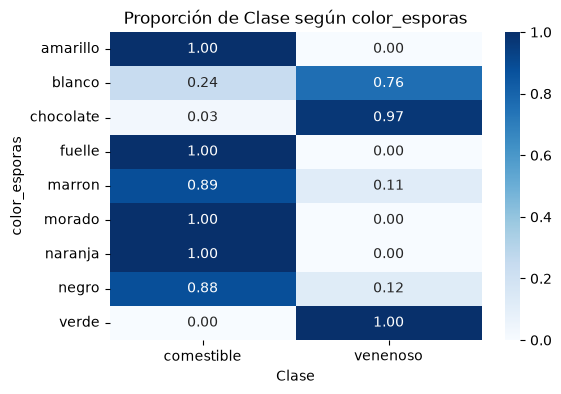

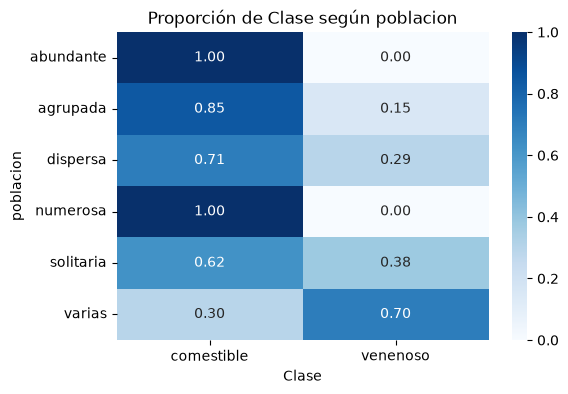

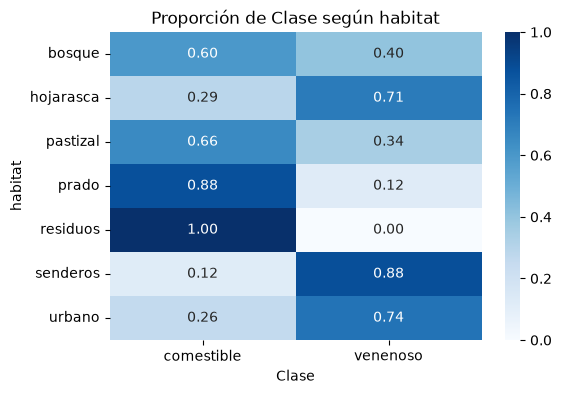

In [22]:
for col in df.columns:
    if col != 'clase':
        tabla = pd.crosstab(df[col], df['clase'], normalize='index')

        plt.figure(figsize=(6,4))
        sns.heatmap(tabla, annot=True, cmap='Blues', fmt='.2f')
        plt.title(f'Proporción de Clase según {col}')
        plt.xlabel('Clase')
        plt.ylabel(col)

        plt.show()

### Pruebas de hipótesis

#### Chi-cuadrado y V de Cramér

Usaremos prueba chi cuadrado para ver si 2 variables están relacionadas, luego V de Cramér para ver qué tan fuerte es la relación. 

Para esto se multiplican las siguientes matrices:
- Binario: 1 si p < 0.05 en chi cuadrado
- V de Cramér

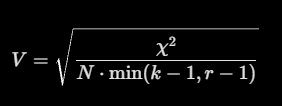

Y por tanto se genera una matriz de calor

In [23]:
def calcular_cramer_y_p(x, y):
    # Crea la tabla de contingencia
    tabla = pd.crosstab(x, y)
    
    # Calcula chi2 y p
    chi2, p, _, _= chi2_contingency(tabla)
    
    # tamaño muestra N y dimensiones de la tabla r y k
    n = tabla.sum().sum()
    r, k = tabla.shape
    
    # Evita division por cero si solo hay 1 categoria
    denominador = min(k-1, r-1)
    if denominador == 0:
        return 0.0, 1.0
    
    # Calcula V de Cramér
    v = np.sqrt(chi2 / (n*denominador))

    return v, p

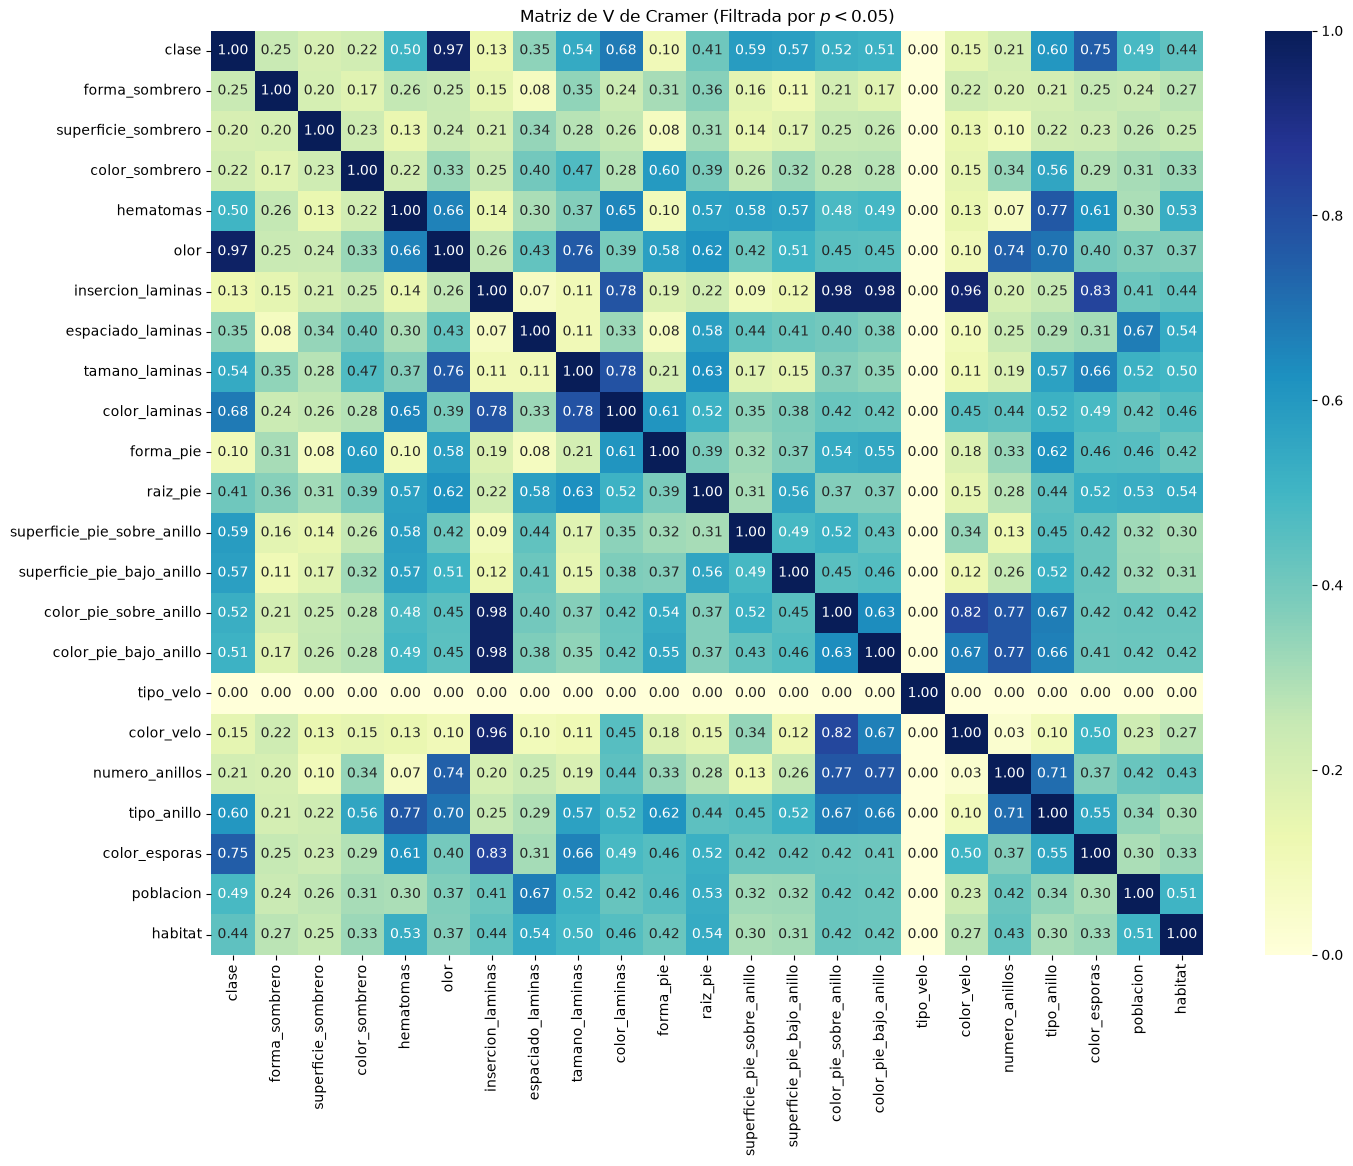

In [24]:
# Creacion de matrices
cols = df.columns
matriz_v = pd.DataFrame(index=cols, columns=cols, dtype=float)
mascara_p = pd.DataFrame(index=cols, columns= cols, dtype=float)

# Rellenar matrices
for i in cols:
    for j in cols:
        if i==j:
            matriz_v.loc[i,j] = 1.0
            mascara_p.loc[i,j] = 1.0
        else:
            v, p = calcular_cramer_y_p(df[i], df[j])
            matriz_v.loc[i,j] = v
            mascara_p.loc[i,j] = 1.0 if p < 0.05 else 0.0

# Multiplicación elemento a elemento
matriz_filtrada = matriz_v * mascara_p

# Graficar en seaborn
plt.figure(figsize = (16,12))
sns.heatmap(matriz_filtrada, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Matriz de V de Cramer (Filtrada por $p < 0.05$)")
plt.show()


Notamos que:
- La clase podría explicarse por el olor, el color de las esporas, el color de las láminas y el tipo de anillos.
- El olor está fuertemente relacionado a la clase.
- El olor está relacionado a variables como: el tamaño de las láminas, el número de anillos y el tipo de anillo.
- La inserción laminar contiene practicamente la misma información que el color pie sobre anillo, color pie bajo anillo y color velo.
- El tipo velo solo se relaciona a sí mismo.

## One Hot Enconding

### Preprocesamiento

In [25]:
# Eliminamos el tipo de velo ya que solo correlaciona consigo mismo y tiene una única categoría
df.drop(columns=["tipo_velo"], inplace=True)

In [26]:
y = (df['clase'] == 'comestible').astype(int)

X_raw = df.drop(columns=['clase'])

X_OHE = pd.get_dummies(X_raw, dtype = int)

df_OHE = X_OHE.copy()

df_OHE['comestible'] = y

In [27]:
df_OHE.columns

Index(['forma_sombrero_campana', 'forma_sombrero_conico',
       'forma_sombrero_convexo', 'forma_sombrero_hundido',
       'forma_sombrero_nudoso', 'forma_sombrero_plano',
       'superficie_sombrero_escamosa', 'superficie_sombrero_fibrosa',
       'superficie_sombrero_suave', 'superficie_sombrero_surcos',
       ...
       'poblacion_solitaria', 'poblacion_varias', 'habitat_bosque',
       'habitat_hojarasca', 'habitat_pastizal', 'habitat_prado',
       'habitat_residuos', 'habitat_senderos', 'habitat_urbano', 'comestible'],
      dtype='str', length=117)

In [28]:
df_OHE[["olor_ninguno","comestible"]].value_counts()

olor_ninguno  comestible
0             0             3796
1             1             3408
0             1              800
1             0              120
Name: count, dtype: int64

## Clustering

### MCA

In [29]:
!pip install prince


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
import prince

mca = prince.MCA(
    n_components=2,
    n_iter=3,
    copy=True,
    check_input=True,
    engine='sklearn',
    random_state=42
)

mca = mca.fit(X_raw)

print("Varianza/Inercia explicada por cada componente:")
print(mca.percentage_of_variance_)

Varianza/Inercia explicada por cada componente:
[7.50882385 7.30975623]


In [31]:
contribuciones = mca.column_contributions_
print(contribuciones)

                                0         1
forma_sombrero__campana  0.010263  0.000481
forma_sombrero__conico   0.000063  0.000090
forma_sombrero__convexo  0.000006  0.002376
forma_sombrero__hundido  0.000204  0.000130
forma_sombrero__nudoso   0.000576  0.029700
...                           ...       ...
habitat__pastizal        0.002628  0.012960
habitat__prado           0.007603  0.003969
habitat__residuos        0.003223  0.003959
habitat__senderos        0.020401  0.002717
habitat__urbano          0.002039  0.001917

[116 rows x 2 columns]


C:\Users\diego\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\diego\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127812 (\N{MUSHROOM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


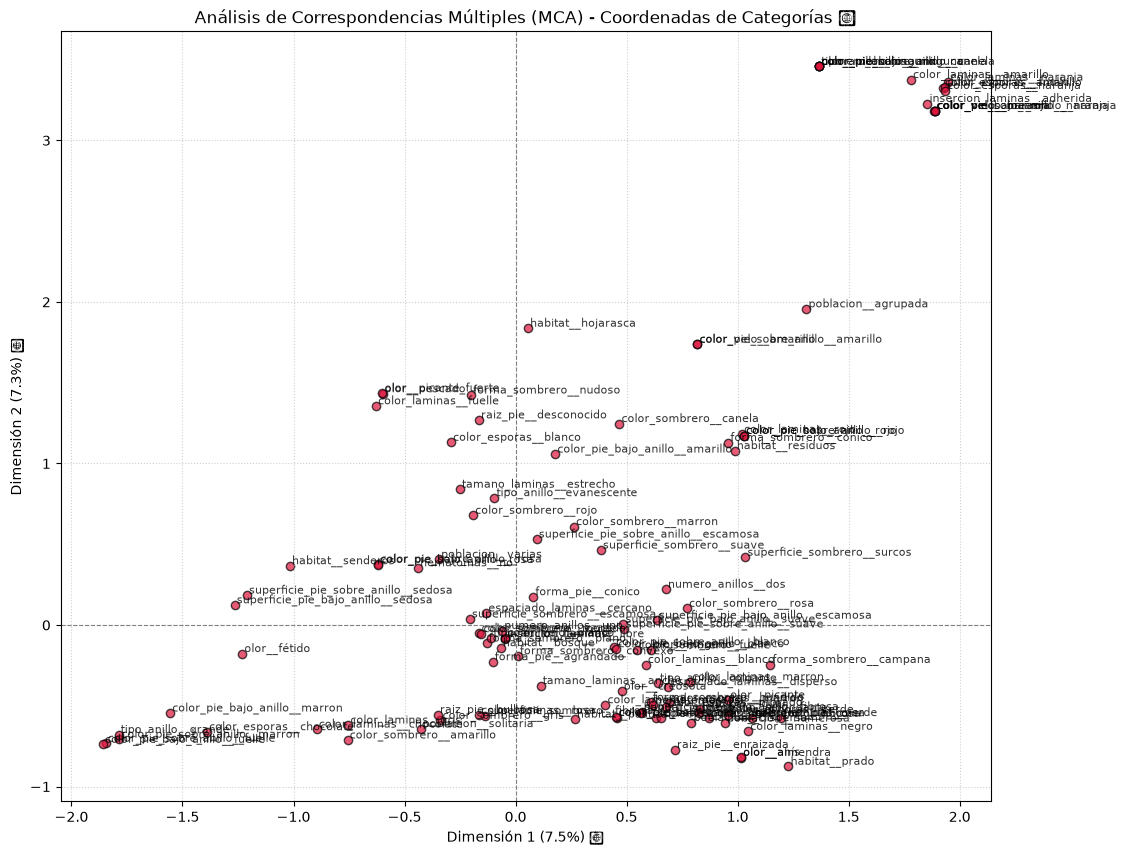

In [32]:
# 1. Obtener las coordenadas de las columnas (categorías) 📍
col_coords = mca.column_coordinates(X_raw)

# 2. Crear la figura 🎨
plt.figure(figsize=(12, 10))

# 3. Graficar los puntos de las categorías 📌
plt.scatter(col_coords[0], col_coords[1], alpha=0.7, color='crimson', edgecolors='k')

# 4. Agregar etiquetas a cada punto 🏷️
for category, (x, y) in col_coords.iterrows():
    plt.text(x + 0.01, y + 0.01, category, fontsize=8, alpha=0.8)

# 5. Líneas de origen y formato 📐
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.8)

plt.xlabel(f"Dimensión 1 ({mca.percentage_of_variance_[0]:.1f}%) 📊")
plt.ylabel(f"Dimensión 2 ({mca.percentage_of_variance_[1]:.1f}%) 📊")
plt.title("Análisis de Correspondencias Múltiples (MCA) - Coordenadas de Categorías 🍄")
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

C:\Users\diego\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\diego\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127812 (\N{MUSHROOM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


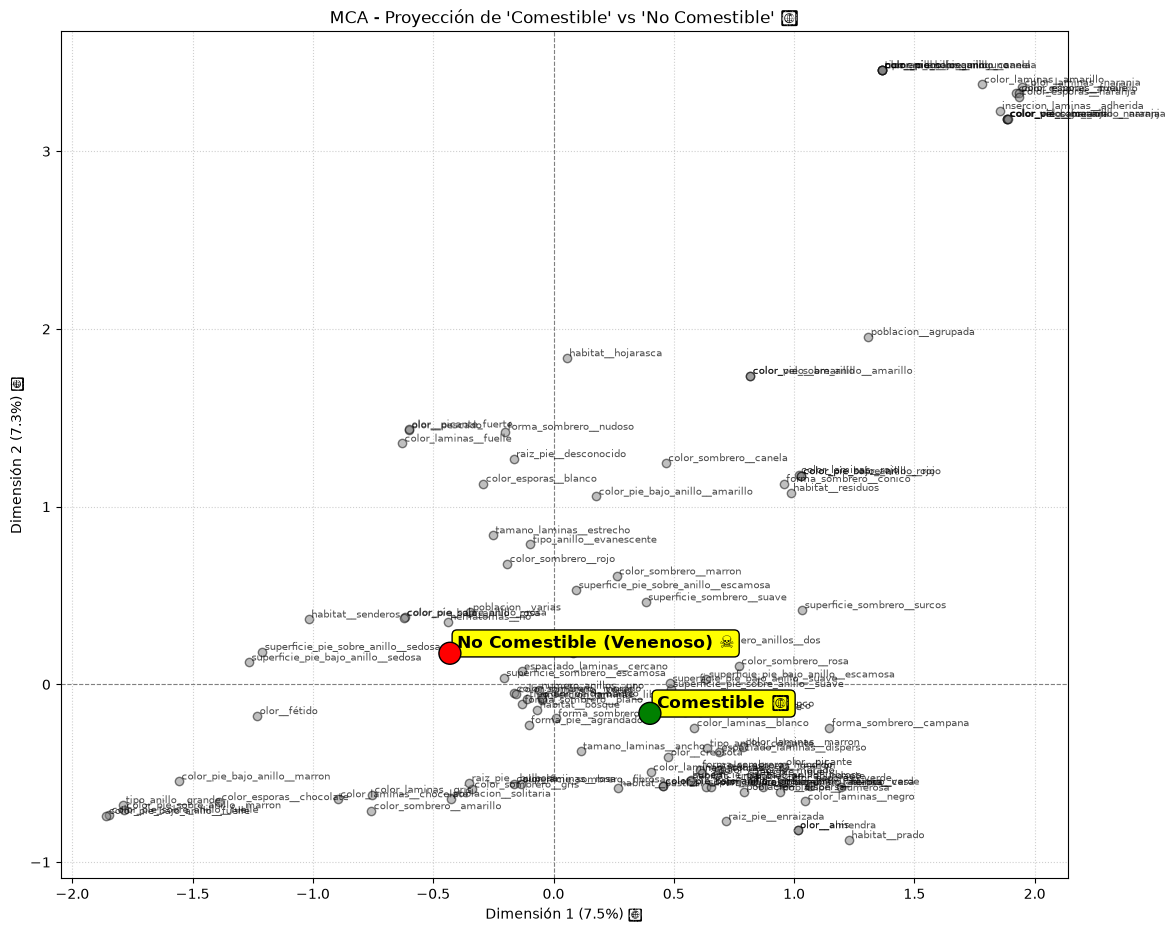

In [33]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Asegurar que tenemos el vector de la variable objetivo correcta 🎯
# Tomamos la columna 'clase' del dataframe original 'df'
y_vec = (df['clase'] == 'comestible').astype(int)

# 2. Obtener coordenadas de características 📍
col_coords = mca.column_coordinates(X_raw)

# 3. Obtener coordenadas de filas y asociar la variable objetivo 📊
row_coords = mca.row_coordinates(X_raw)
df_coords = row_coords.copy()
df_coords['comestible'] = y_vec.values

# 4. Calcular el centroide (promedio) para cada clase 🎯
target_coords = df_coords.groupby('comestible').mean()
target_coords.index = ['No Comestible (Venenoso) ☠️️', 'Comestible 🍄']

# 5. Graficar 🎨
plt.figure(figsize=(13, 11))

# Características (puntos grises)
plt.scatter(col_coords[0], col_coords[1], alpha=0.5, color='gray', edgecolors='k')

for category, (x, y_pos) in col_coords.iterrows():
    plt.text(x + 0.01, y_pos + 0.01, category, fontsize=7, alpha=0.7)

# Centroides Objetivo (Comestible vs No Comestible)
plt.scatter(target_coords[0], target_coords[1], color=['red', 'green'], s=250, edgecolors='black', zorder=5)

for label, (x, y_pos) in target_coords.iterrows():
    plt.text(x + 0.03, y_pos + 0.03, label, fontsize=12, fontweight='bold', 
             bbox=dict(boxstyle="round,pad=0.3", fc="yellow", ec="black", lw=1))

# Formato de ejes 📐
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.8)

plt.xlabel(f"Dimensión 1 ({mca.percentage_of_variance_[0]:.1f}%) 📊")
plt.ylabel(f"Dimensión 2 ({mca.percentage_of_variance_[1]:.1f}%) 📊")
plt.title("MCA - Proyección de 'Comestible' vs 'No Comestible' 🍄")
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

C:\Users\diego\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\diego\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127812 (\N{MUSHROOM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


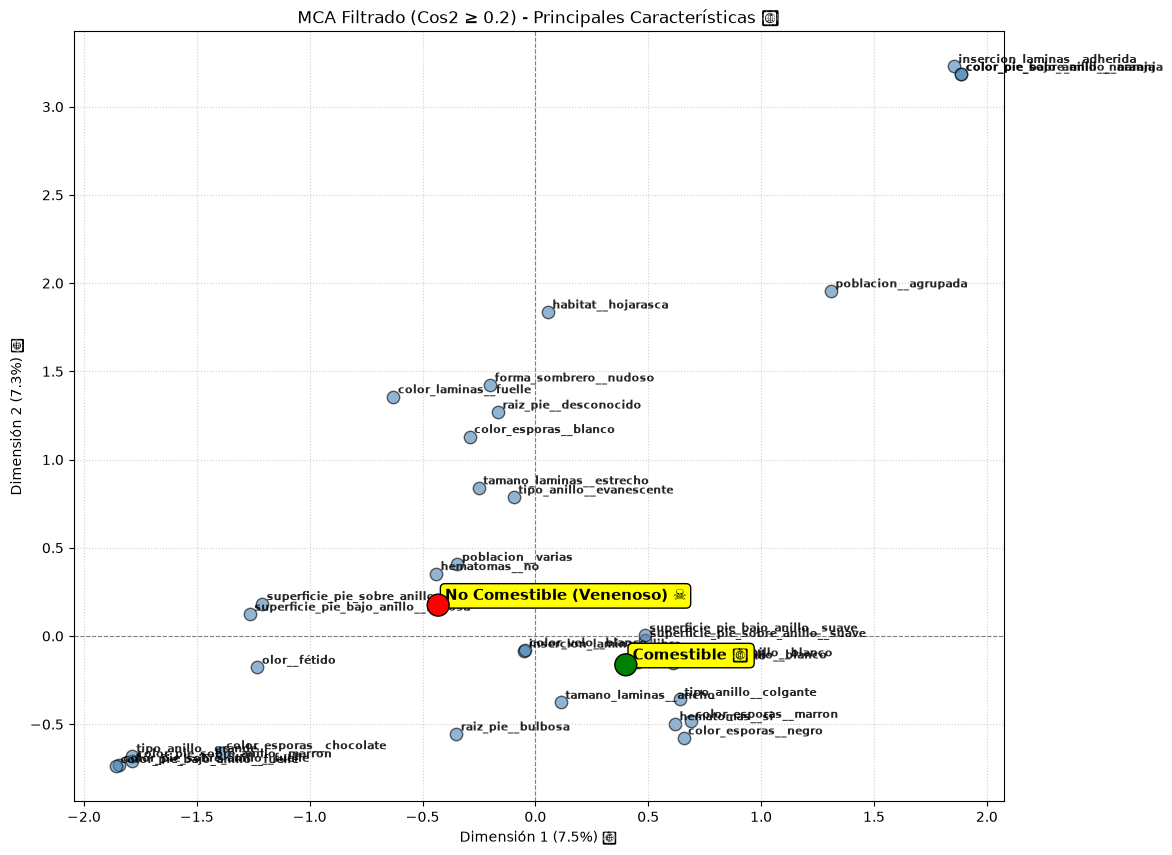

In [34]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Obtener la tabla de Cos2 y calcular la suma de las dos primeras dimensiones 🧮
cos2 = mca.column_cosine_similarities(X_raw)
cos2_total = cos2[0] + cos2[1]

# 2. Filtrar las categorías con Cos2 >= 0.2 🎯
categorias_representativas = cos2_total[cos2_total >= 0.2].index

# 3. Filtrar las coordenadas de las columnas para conservar solo las elegidas 📍
col_coords_filtradas = col_coords.loc[categorias_representativas]

# 4. Asegurar el vector de la variable objetivo y sus centroides 🎯
y_vec = (df['clase'] == 'comestible').astype(int)
row_coords = mca.row_coordinates(X_raw)
df_coords = row_coords.copy()
df_coords['comestible'] = y_vec.values

target_coords = df_coords.groupby('comestible').mean()
target_coords.index = ['No Comestible (Venenoso) ☠️', 'Comestible 🍄']

# 5. Crear la figura limpia 🎨
plt.figure(figsize=(12, 10))

# Graficar solo las características filtradas (puntos grises)
plt.scatter(col_coords_filtradas[0], col_coords_filtradas[1], alpha=0.6, color='steelblue', edgecolors='k', s=80)

for category, (x, y_pos) in col_coords_filtradas.iterrows():
    plt.text(x + 0.02, y_pos + 0.02, category, fontsize=8, fontweight='bold', alpha=0.85)

# Graficar los centroides objetivo (Comestible vs No Comestible)
plt.scatter(target_coords[0], target_coords[1], color=['red', 'green'], s=250, edgecolors='black', zorder=5)

for label, (x, y_pos) in target_coords.iterrows():
    plt.text(x + 0.03, y_pos + 0.03, label, fontsize=11, fontweight='bold', 
             bbox=dict(boxstyle="round,pad=0.3", fc="yellow", ec="black", lw=1))

# Líneas del plano cartesiano 📐
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.8)

plt.xlabel(f"Dimensión 1 ({mca.percentage_of_variance_[0]:.1f}%) 📊")
plt.ylabel(f"Dimensión 2 ({mca.percentage_of_variance_[1]:.1f}%) 📊")
plt.title("MCA Filtrado (Cos2 ≥ 0.2) - Principales Características 🍄")
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

### K-Modes


In [35]:
#!pip install kModes

K=1 -> Costo: 74778.0
K=2 -> Costo: 62534.0
K=3 -> Costo: 53479.0
K=4 -> Costo: 48583.0
K=5 -> Costo: 45596.0
K=6 -> Costo: 44295.0
K=7 -> Costo: 41749.0
K=8 -> Costo: 39979.0


C:\Users\diego\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\diego\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127812 (\N{MUSHROOM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\diego\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128290 (\N{INPUT SYMBOL FOR NUMBERS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


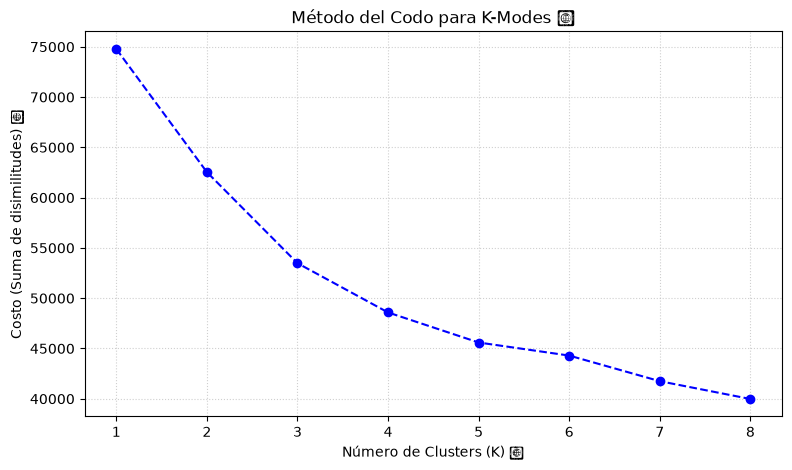

In [36]:
from kmodes.kmodes import KModes

# 1. Definir el rango de K a probar 🧪
costos = []
K_rango = range(1, 9)

# 2. Calcular el costo para cada valor de K 🔄
for k in K_rango:
    km = KModes(n_clusters=k, init='Huang', n_init=5, random_state=42)
    km.fit(X_raw)
    costos.append(km.cost_)
    print(f"K={k} -> Costo: {km.cost_}")

# 3. Graficar la curva del codo 📊
plt.figure(figsize=(9, 5))
plt.plot(K_rango, costos, marker='o', linestyle='--', color='b')
plt.xlabel('Número de Clusters (K) 🔢')
plt.ylabel('Costo (Suma de disimilitudes) 📉')
plt.title('Método del Codo para K-Modes 🍄')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [37]:
km2 = KModes(n_clusters=2, init='Huang', n_init=5, random_state=42)

clusters2 = km2.fit_predict(X_raw)

# Creamos la tabla cruzada entre los clusters y la variable real 'clase' 📊
tabla_comparativa2 = pd.crosstab(clusters2, df['clase'], colnames=['Clase Real'], rownames=['Cluster K-Modes'])

print(tabla_comparativa2)

Clase Real       comestible  venenoso
Cluster K-Modes                      
0                        80      3052
1                      4128       864


In [38]:
# 1. Obtener los centroides (modas) del modelo de 3 clusters 👑
centroides = pd.DataFrame(km2.cluster_centroids_, columns=X_raw.columns)

# 2. Filtrar solo la fila del Cluster 2 (índice 2) 🎯
modas_cluster_0 = centroides.iloc[0]

# 3. Mostrar las características principales del Cluster 2 📊
print("PERFIL DEL CLUSTER 0")
print(modas_cluster_0)

PERFIL DEL CLUSTER 0
forma_sombrero                       plano
superficie_sombrero               escamosa
color_sombrero                      marron
hematomas                               no
olor                                fétido
insercion_laminas                    libre
espaciado_laminas                  cercano
tamano_laminas                    estrecho
color_laminas                       fuelle
forma_pie                           conico
raiz_pie                       desconocido
superficie_pie_sobre_anillo         sedosa
superficie_pie_bajo_anillo          sedosa
color_pie_sobre_anillo                rosa
color_pie_bajo_anillo                 rosa
color_velo                          blanco
numero_anillos                         uno
tipo_anillo                    evanescente
color_esporas                       blanco
poblacion                           varias
habitat                             bosque
Name: 0, dtype: str


In [39]:
km3 = KModes(n_clusters=3, init='Huang', n_init=5, random_state=42)

clusters3 = km3.fit_predict(X_raw)

# Creamos la tabla cruzada entre los clusters y la variable real 'clase' 📊
tabla_comparativa3 = pd.crosstab(clusters3, df['clase'], colnames=['Clase Real'], rownames=['Cluster K-Modes'])

print(tabla_comparativa3)

Clase Real       comestible  venenoso
Cluster K-Modes                      
0                      1584      1893
1                      2624       688
2                         0      1335


In [40]:
# 1. Obtener los centroides (modas) del modelo de 3 clusters 👑
centroides = pd.DataFrame(km3.cluster_centroids_, columns=X_raw.columns)

# 2. Filtrar solo la fila del Cluster 2 (índice 2) 🎯
modas_cluster_2 = centroides.iloc[2]

# 3. Mostrar las características principales del Cluster 2 📊
print("PERFIL DEL CLUSTER 2")
print(modas_cluster_2)

PERFIL DEL CLUSTER 2
forma_sombrero                   convexo
superficie_sombrero             escamosa
color_sombrero                  amarillo
hematomas                             no
olor                              fétido
insercion_laminas                  libre
espaciado_laminas                cercano
tamano_laminas                     ancho
color_laminas                  chocolate
forma_pie                      agrandado
raiz_pie                         bulbosa
superficie_pie_sobre_anillo       sedosa
superficie_pie_bajo_anillo        sedosa
color_pie_sobre_anillo              rosa
color_pie_bajo_anillo               rosa
color_velo                        blanco
numero_anillos                       uno
tipo_anillo                       grande
color_esporas                  chocolate
poblacion                         varias
habitat                           bosque
Name: 2, dtype: str


Caracteristicas compartidas cluster 0 2 kmodes y cluster 2 3 kmodes

- Olor: fétido
- Superficie del sombrero: escamosa
- Superficie del pie (sobre el anillo): sedosa
- Superficie del pie (bajo el anillo): sedosa
- Color del pie (sobre el anillo): rosa
- Color del pie (bajo el anillo): rosa
- Color del velo: blanco
- Número de anillos: uno
- Inserción de láminas: libre
- Espaciado de láminas: cercano
- Hematomas: no
- Población: varias
- Hábitat: bosque

## Machine Learning

### Preprocesamiento

In [41]:
columnas_a_eliminar = [
    'insercion_laminas',
    'forma_sombrero',
    'superficie_sombrero',
    'color_sombrero',
    'color_velo',
    'numero_anillos'
]

df_filtrado = df.drop(columns = columnas_a_eliminar)

print(f"columnas restantes: {df_filtrado.shape[1]}")

columnas restantes: 16


In [42]:
!pip install scikit-learn


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

X = df_filtrado.drop(columns=['clase'])
y = df_filtrado['clase']

X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size = 0.20,
    random_state = 42,
    stratify = y)

print(f"Conjunto de entrenamiento (X_train): {X_train.shape}")
print(f"Conjunto de prueba (X_test): {X_test.shape}")

Conjunto de entrenamiento (X_train): (6499, 15)
Conjunto de prueba (X_test): (1625, 15)


In [44]:
encoder = OneHotEncoder(sparse_output = False, handle_unknown='ignore')

X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

columnas_codificadas = encoder.get_feature_names_out(X_train.columns)

X_train_encoded = pd.DataFrame(X_train_encoded, columns = columnas_codificadas)
X_test_encoded = pd.DataFrame(X_test_encoded, columns= columnas_codificadas)

### DecisionTreeClassifier

#### Modelo a full

In [45]:
modelo_arbol = DecisionTreeClassifier(random_state=42)

modelo_arbol.fit(X_train_encoded, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [46]:
from sklearn.metrics import classification_report, confusion_matrix

# Predicción en el conjunto de test
y_pred = modelo_arbol.predict(X_test_encoded)

# Ver el reporte completo
print("=== REPORTE DE CLASIFICACIÓN ===")
print(classification_report(y_test, y_pred))

# Ver la matriz de confusión en texto
print("=== MATRIZ DE CONFUSIÓN ===")
print(pd.crosstab(y_test, y_pred, rownames=['Real'], colnames=['Predicción']))

=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

  comestible       1.00      1.00      1.00       842
    venenoso       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625

=== MATRIZ DE CONFUSIÓN ===
Predicción  comestible  venenoso
Real                            
comestible         842         0
venenoso             0       783


In [47]:
# 1. Extraer la importancia de cada columna codificada 📊
importancias = pd.DataFrame({
    'Caracteristica': X_train_encoded.columns,
    'Importancia': modelo_arbol.feature_importances_
})

# 2. Ordenar de mayor a menor y filtrar las que tienen importancia mayor a 0 🔝
importancias = importancias.sort_values(by='Importancia', ascending=False)
importancias_usadas = importancias[importancias['Importancia'] > 0]

print("=== CARACTERÍSTICAS MÁS IMPORTANTES EN EL ÁRBOL ===")
print(importancias_usadas)

=== CARACTERÍSTICAS MÁS IMPORTANTES EN EL ÁRBOL ===
                         Caracteristica  Importancia
7                          olor_ninguno     0.617790
30                        raiz_pie_casa     0.179322
32                   raiz_pie_enraizada     0.085038
73                  color_esporas_verde     0.035830
2                         olor_almendra     0.022586
3                             olor_anís     0.021923
41     superficie_pie_bajo_anillo_suave     0.015614
38  superficie_pie_bajo_anillo_escamosa     0.013490
47        color_pie_sobre_anillo_marron     0.005331
0                          hematomas_no     0.002986
13                 tamano_laminas_ancho     0.000090


In [48]:
from sklearn.tree import export_text

# Genera las reglas lógicas en texto simple
reglas = export_text(modelo_arbol, feature_names=list(X_train_encoded.columns))
print(reglas)

|--- olor_ninguno <= 0.50
|   |--- raiz_pie_casa <= 0.50
|   |   |--- raiz_pie_enraizada <= 0.50
|   |   |   |--- olor_almendra <= 0.50
|   |   |   |   |--- olor_anís <= 0.50
|   |   |   |   |   |--- class: venenoso
|   |   |   |   |--- olor_anís >  0.50
|   |   |   |   |   |--- class: comestible
|   |   |   |--- olor_almendra >  0.50
|   |   |   |   |--- class: comestible
|   |   |--- raiz_pie_enraizada >  0.50
|   |   |   |--- class: comestible
|   |--- raiz_pie_casa >  0.50
|   |   |--- superficie_pie_bajo_anillo_suave <= 0.50
|   |   |   |--- class: venenoso
|   |   |--- superficie_pie_bajo_anillo_suave >  0.50
|   |   |   |--- class: comestible
|--- olor_ninguno >  0.50
|   |--- color_esporas_verde <= 0.50
|   |   |--- superficie_pie_bajo_anillo_escamosa <= 0.50
|   |   |   |--- tamano_laminas_ancho <= 0.50
|   |   |   |   |--- hematomas_no <= 0.50
|   |   |   |   |   |--- class: venenoso
|   |   |   |   |--- hematomas_no >  0.50
|   |   |   |   |   |--- class: comestible
|   |   

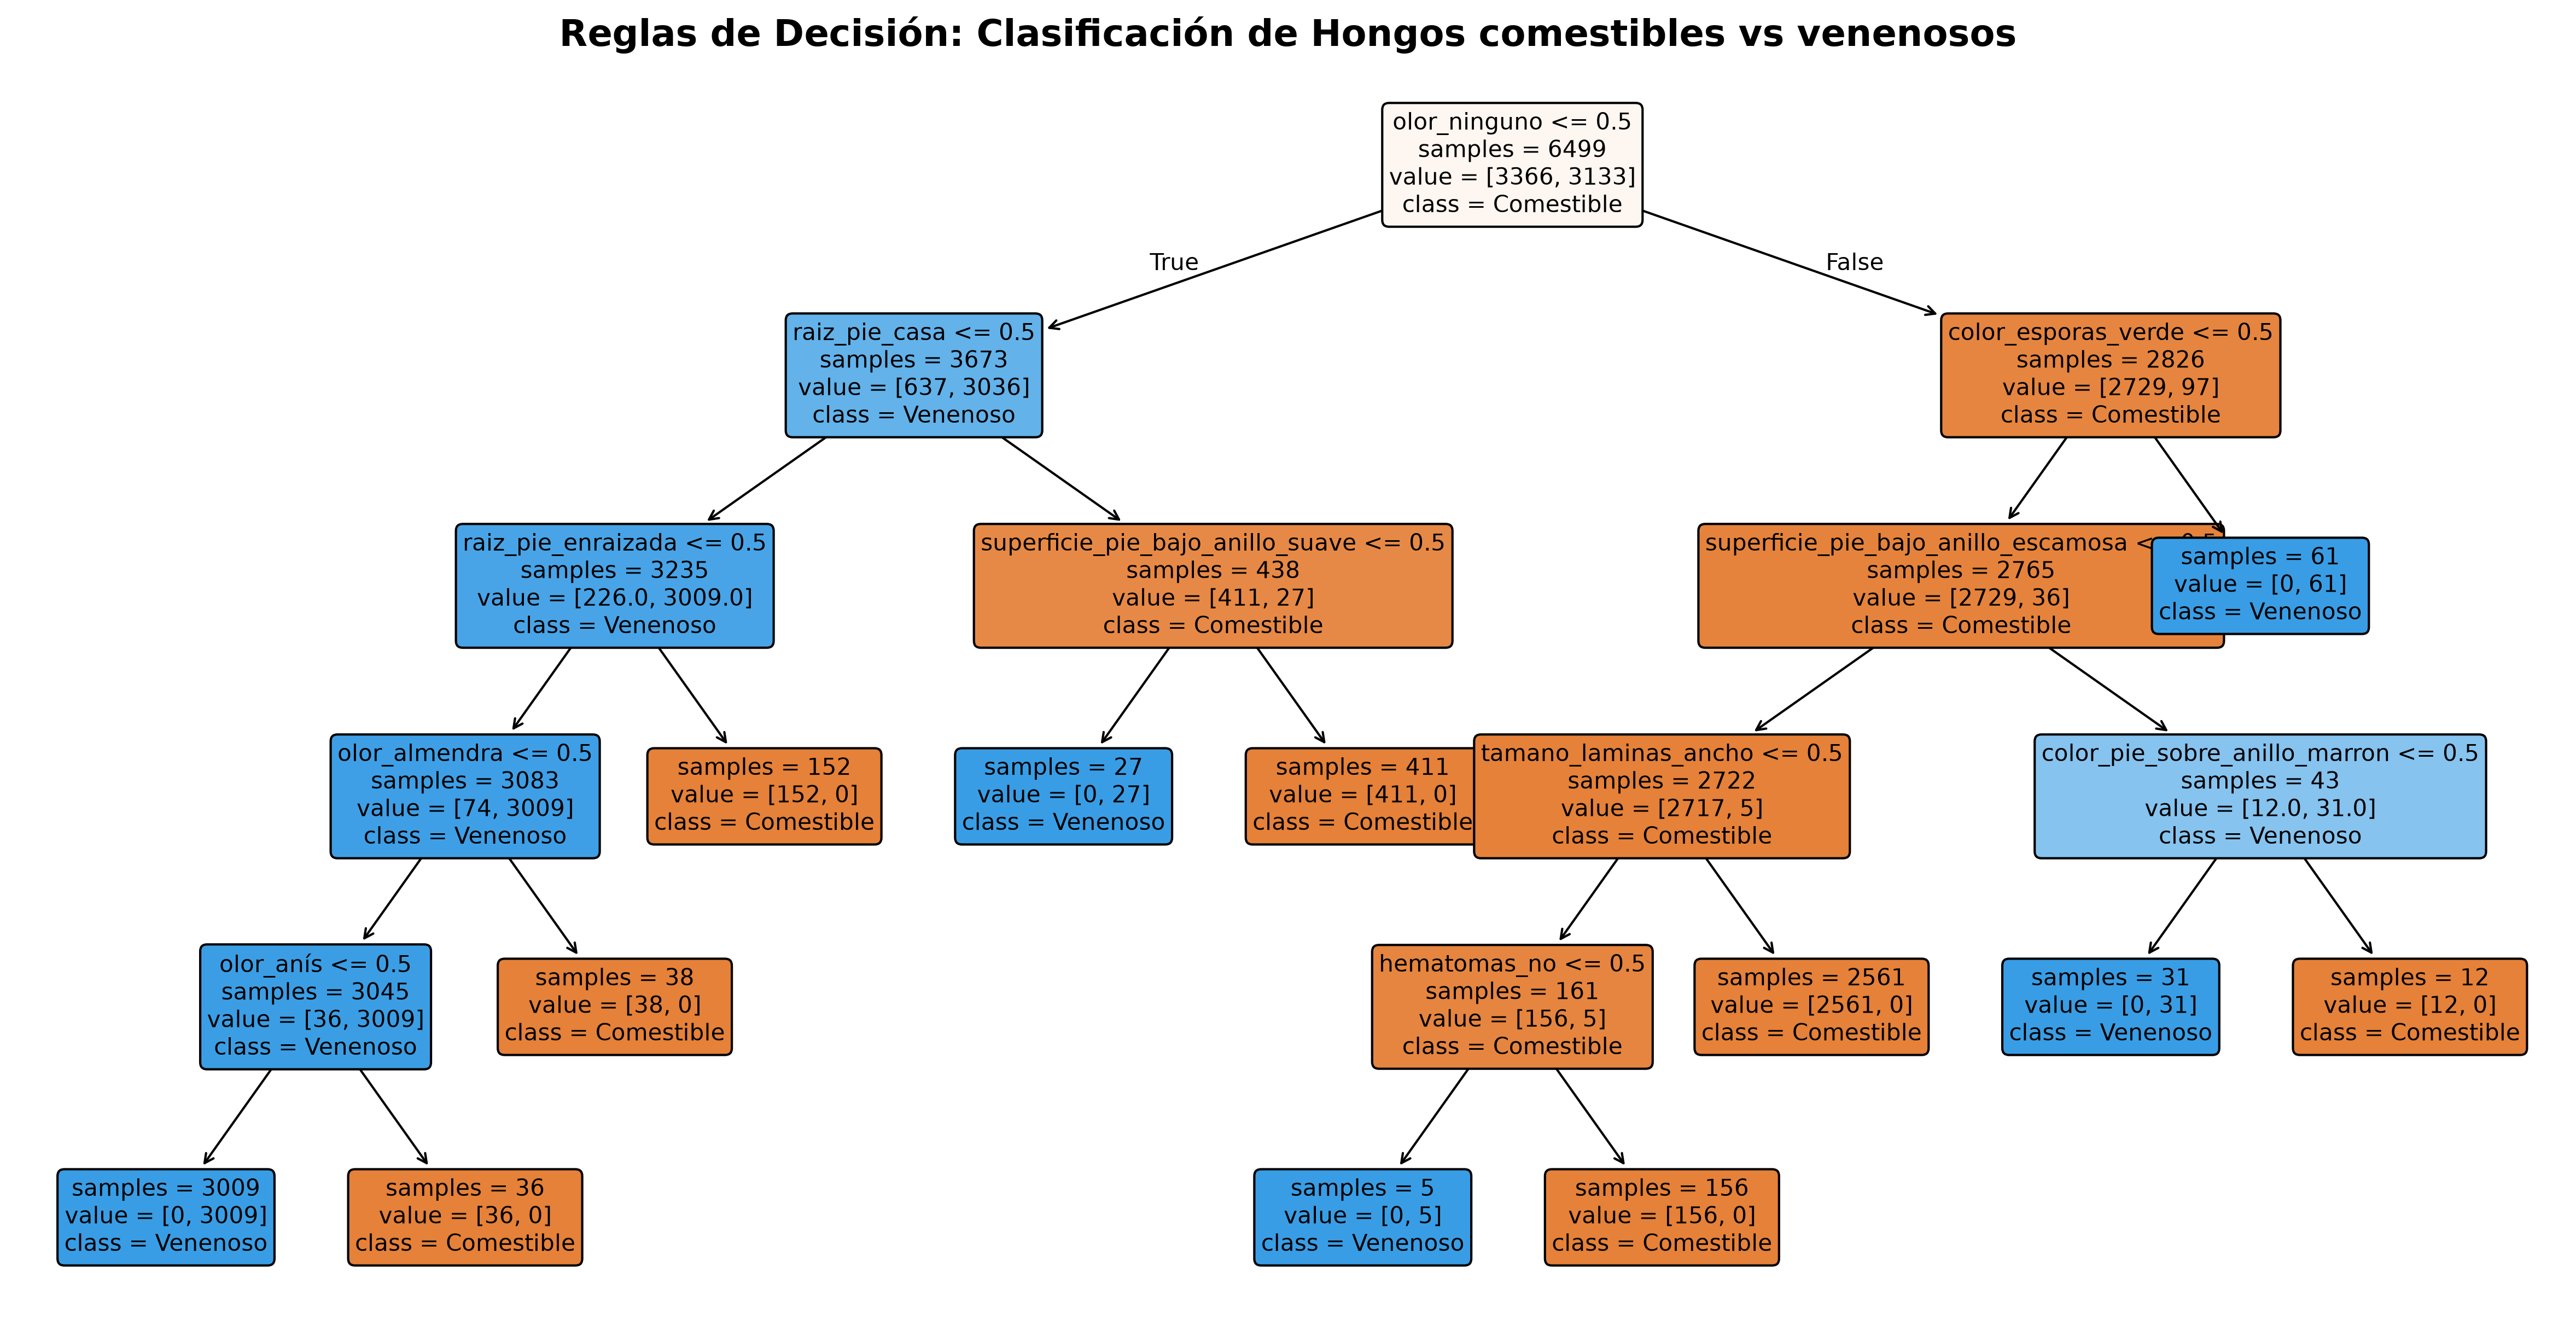

In [49]:
from sklearn.tree import plot_tree
# 1. Configurar el tamaño de la figura (alta resolución)
plt.figure(figsize=(20, 10), dpi=300)

# 2. Dibujar el árbol de decisión
plot_tree(
    modelo_arbol,
    feature_names=X_train_encoded.columns,
    class_names=['Comestible', 'Venenoso'],
    filled=True,         # Colorea los nodos según la clase mayoritaria
    rounded=True,        # Bordes redondeados para mejor estética
    fontsize=10,         # Tamaño de fuente legible
    impurity=False       # Oculta el valor de Gini/Entropía si prefieres un diseño más limpio
)

# 3. Título del gráfico
plt.title("Reglas de Decisión: Clasificación de Hongos comestibles vs venenosos", fontsize=16, fontweight='bold')

# 4. Guardar la imagen para la presentación de gerencia
plt.savefig("arbol_decision_gerencia.png", bbox_inches='tight')

# 5. Mostrar en pantalla
plt.show()

#### Limitado a max depth = 3

In [50]:
modelo_arbol_v2 = DecisionTreeClassifier(random_state=42, max_depth=3)

modelo_arbol_v2.fit(X_train_encoded, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [51]:
from sklearn.metrics import classification_report, confusion_matrix

# Predicción en el conjunto de test
y_pred = modelo_arbol_v2.predict(X_test_encoded)

# Ver el reporte completo
print("=== REPORTE DE CLASIFICACIÓN ===")
print(classification_report(y_test, y_pred))

# Ver la matriz de confusión en texto
print("=== MATRIZ DE CONFUSIÓN ===")
print(pd.crosstab(y_test, y_pred, rownames=['Real'], colnames=['Predicción']))

=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

  comestible       1.00      0.97      0.98       842
    venenoso       0.97      1.00      0.98       783

    accuracy                           0.98      1625
   macro avg       0.98      0.98      0.98      1625
weighted avg       0.98      0.98      0.98      1625

=== MATRIZ DE CONFUSIÓN ===
Predicción  comestible  venenoso
Real                            
comestible         816        26
venenoso             3       780


In [52]:
# 1. Extraer la importancia de cada columna codificada 📊
importancias = pd.DataFrame({
    'Caracteristica': X_train_encoded.columns,
    'Importancia': modelo_arbol_v2.feature_importances_
})

# 2. Ordenar de mayor a menor y filtrar las que tienen importancia mayor a 0 🔝
importancias = importancias.sort_values(by='Importancia', ascending=False)
importancias_usadas = importancias[importancias['Importancia'] > 0]

print("=== CARACTERÍSTICAS MÁS IMPORTANTES EN EL ÁRBOL ===")
print(importancias_usadas)

=== CARACTERÍSTICAS MÁS IMPORTANTES EN EL ÁRBOL ===
                         Caracteristica  Importancia
7                          olor_ninguno     0.652308
30                        raiz_pie_casa     0.189342
32                   raiz_pie_enraizada     0.089789
73                  color_esporas_verde     0.037831
41     superficie_pie_bajo_anillo_suave     0.016486
38  superficie_pie_bajo_anillo_escamosa     0.014243


In [53]:
from sklearn.tree import export_text

# Genera las reglas lógicas en texto simple
reglas = export_text(modelo_arbol_v2, feature_names=list(X_train_encoded.columns))
print(reglas)

|--- olor_ninguno <= 0.50
|   |--- raiz_pie_casa <= 0.50
|   |   |--- raiz_pie_enraizada <= 0.50
|   |   |   |--- class: venenoso
|   |   |--- raiz_pie_enraizada >  0.50
|   |   |   |--- class: comestible
|   |--- raiz_pie_casa >  0.50
|   |   |--- superficie_pie_bajo_anillo_suave <= 0.50
|   |   |   |--- class: venenoso
|   |   |--- superficie_pie_bajo_anillo_suave >  0.50
|   |   |   |--- class: comestible
|--- olor_ninguno >  0.50
|   |--- color_esporas_verde <= 0.50
|   |   |--- superficie_pie_bajo_anillo_escamosa <= 0.50
|   |   |   |--- class: comestible
|   |   |--- superficie_pie_bajo_anillo_escamosa >  0.50
|   |   |   |--- class: venenoso
|   |--- color_esporas_verde >  0.50
|   |   |--- class: venenoso



c:\Users\diego\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\tree\_export.py:686: UserWarning: Glyph 127812 (\N{MUSHROOM}) missing from font(s) DejaVu Sans.
  ann.update_bbox_position_size(renderer)
C:\Users\diego\AppData\Local\Temp\ipykernel_38240\3636284487.py:20: UserWarning: Glyph 127812 (\N{MUSHROOM}) missing from font(s) DejaVu Sans.
  plt.savefig("arbol_decision_gerencia.png", bbox_inches='tight')
C:\Users\diego\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127812 (\N{MUSHROOM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


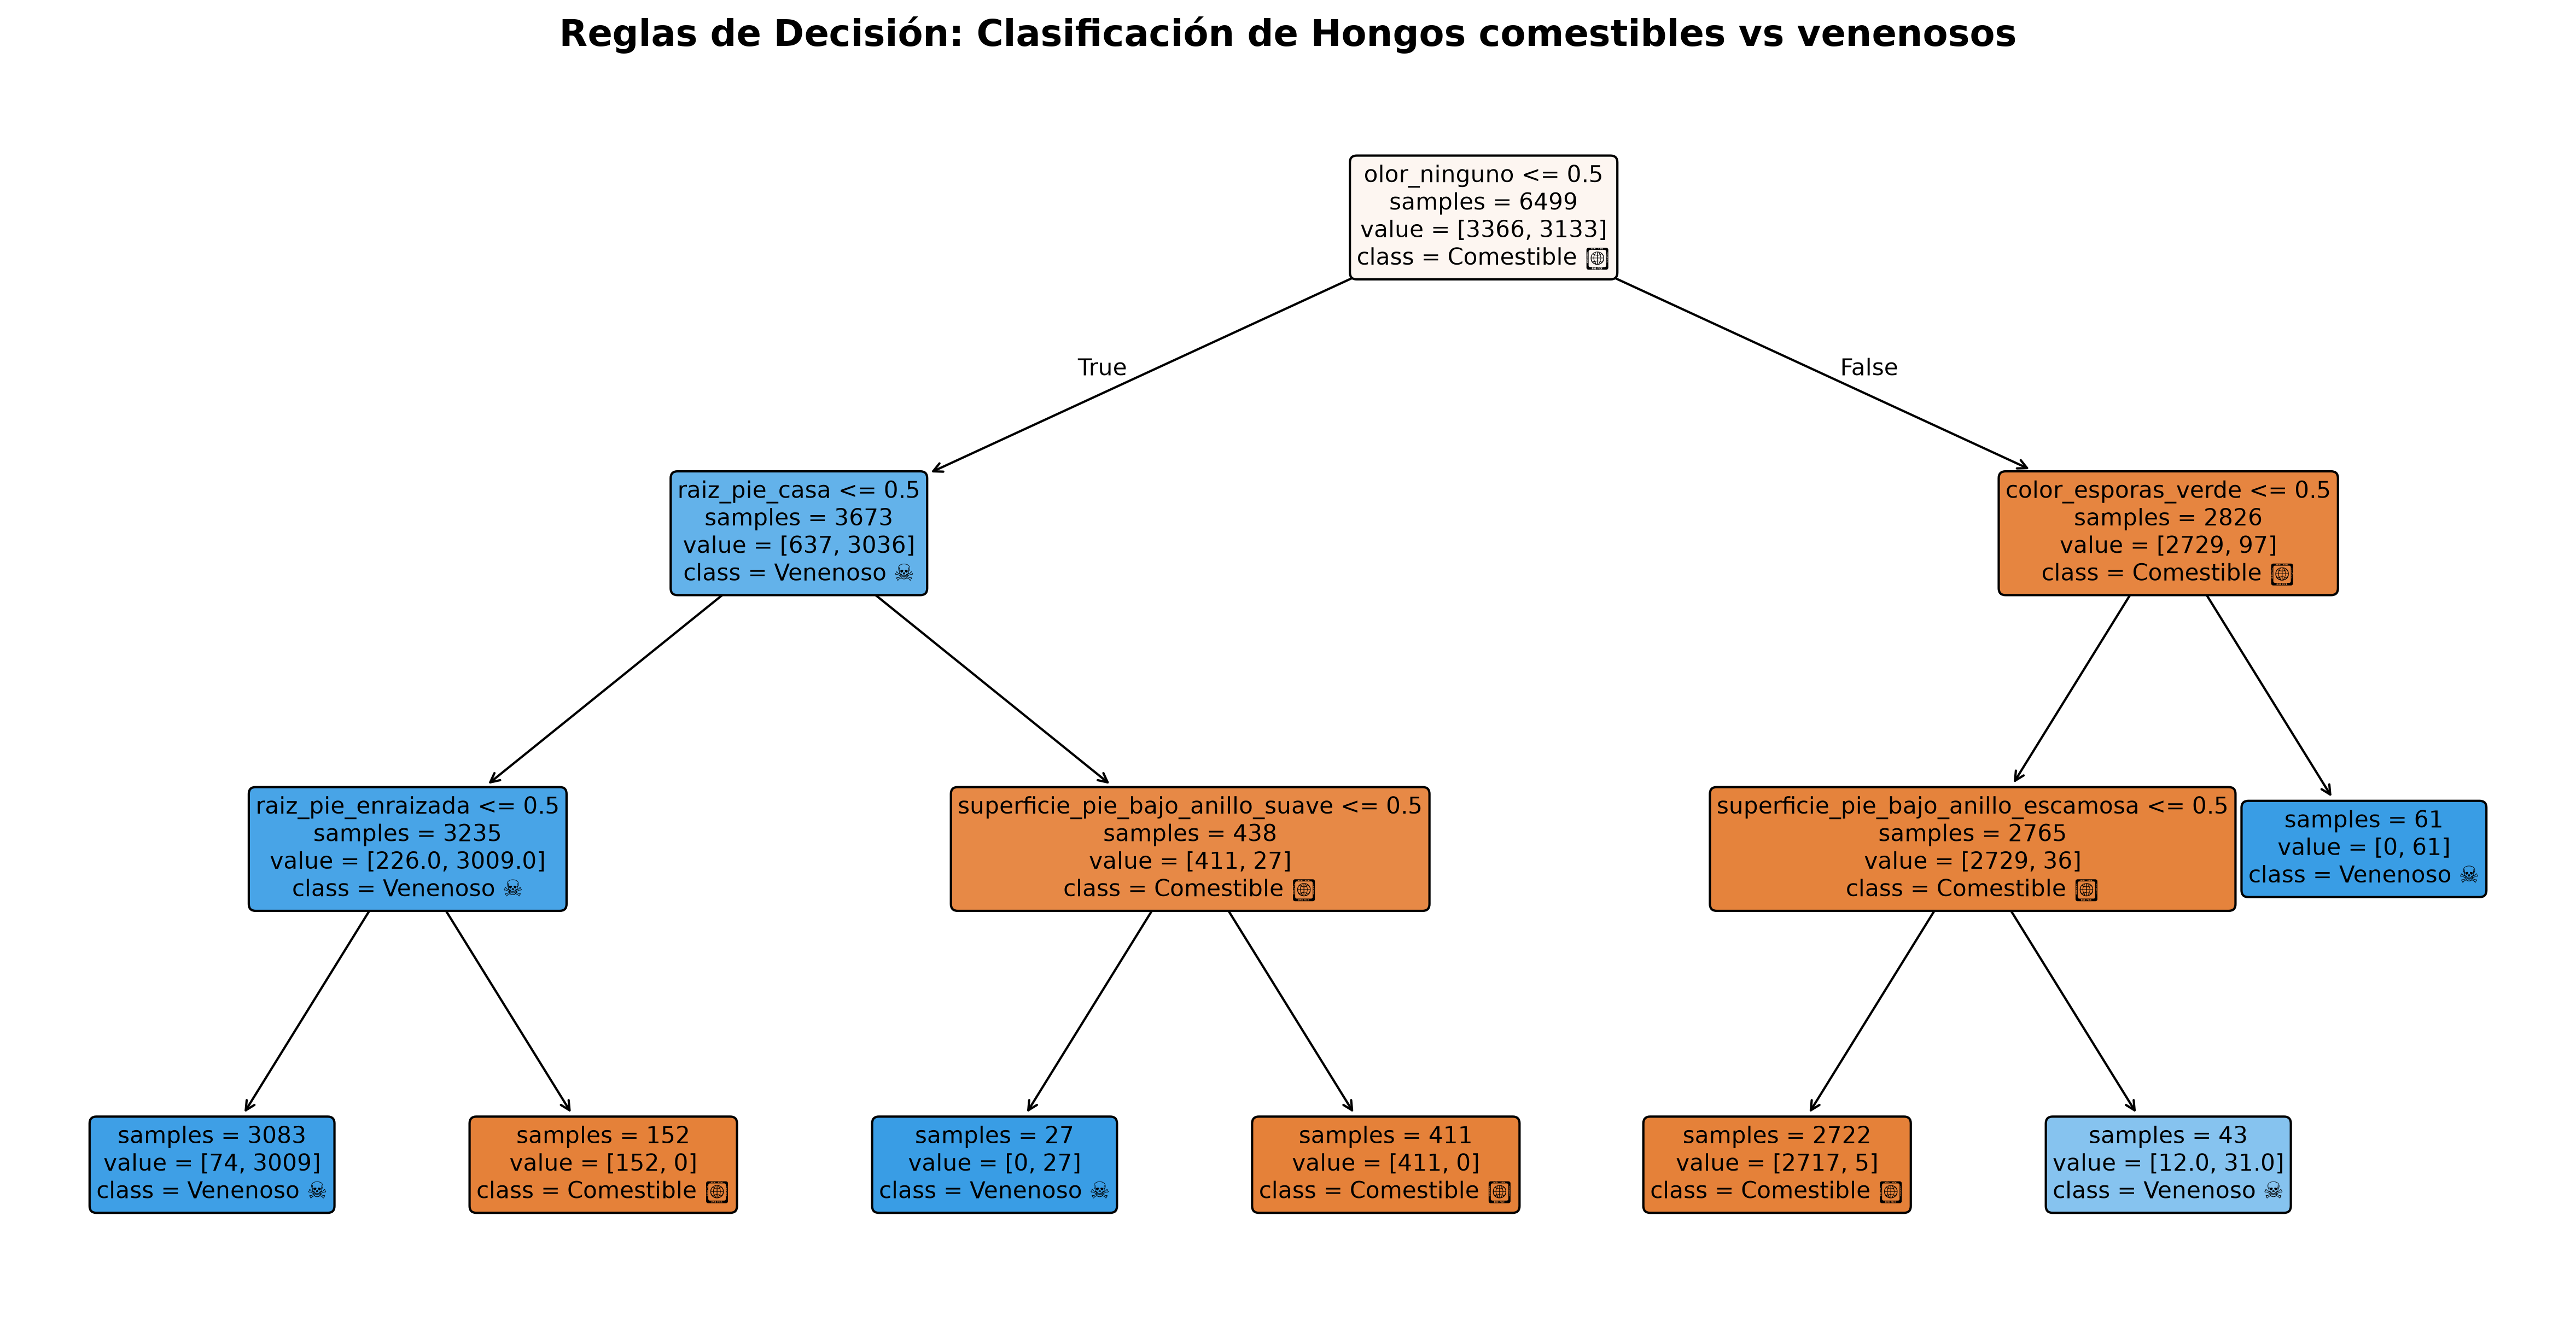

In [54]:
from sklearn.tree import plot_tree
# 1. Configurar el tamaño de la figura (alta resolución)
plt.figure(figsize=(20, 10), dpi=300)

# 2. Dibujar el árbol de decisión
plot_tree(
    modelo_arbol_v2,
    feature_names=X_train_encoded.columns,
    class_names=['Comestible 🍄', 'Venenoso ☠️'],
    filled=True,         # Colorea los nodos según la clase mayoritaria
    rounded=True,        # Bordes redondeados para mejor estética
    fontsize=10,         # Tamaño de fuente legible
    impurity=False       # Oculta el valor de Gini/Entropía si prefieres un diseño más limpio
)

# 3. Título del gráfico
plt.title("Reglas de Decisión: Clasificación de Hongos comestibles vs venenosos", fontsize=16, fontweight='bold')

# 4. Guardar la imagen para la presentación de gerencia
plt.savefig("arbol_decision_gerencia.png", bbox_inches='tight')

# 5. Mostrar en pantalla
plt.show()

#### Optimizar umbral para que ninguno sea venenoso

In [55]:
from sklearn.metrics import classification_report, confusion_matrix

umbral_comestible = 0.99

probabilidades = modelo_arbol.predict_proba(X_test_encoded)

y_pred_optimizado = np.where(
    probabilidades[:, 0] >= umbral_comestible,
    'comestible',
    'venenoso'
)

print("Matriz de confusión")
matriz_optimizado = pd.crosstab(
    y_test, 
    y_pred_optimizado,
    rownames=['Real'],
    colnames=['Predicción']
)
print(matriz_optimizado)

Matriz de confusión
Predicción  comestible  venenoso
Real                            
comestible         842         0
venenoso             0       783


In [56]:
probabilidades = modelo_arbol_v2.predict_proba(X_test_encoded)

y_pred_optimizado = np.where(
    probabilidades[:, 0] >= umbral_comestible,
    'comestible',
    'venenoso'
)

print("Matriz de confusión")
matriz_optimizado = pd.crosstab(
    y_test, 
    y_pred_optimizado,
    rownames=['Real'],
    colnames=['Predicción']
)
print(matriz_optimizado)

Matriz de confusión
Predicción  comestible  venenoso
Real                            
comestible         816        26
venenoso             3       780


### Conclusión

Se propone la siguiente heurística de producción basada en 3 caminos de reglas jerarquizadas:

<ol>
  <li><strong>Producción del 80%</strong>
    <ul>
      <li>1.1. No tiene olor</li>
      <li>1.2. Las esporas no son verdes</li>
      <li>1.3. La superficie bajo anillos no es escamosa</li>
      <li>1.4. No tiene hematomas</li>
    </ul>
  </li>
  <li><strong>Producción del 12%</strong>
    <ul>
      <li>2.1. Tiene olor</li>
      <li>2.2. No tiene raiz pie casa</li>
      <li>2.3. Superficie bajo anillo no es suave</li>
    </ul>
  </li>
  <li><strong>Producción del 4.5%</strong>
    <ul>
      <li>3.1. No tiene olor</li>
      <li>3.2. Tiene raiz pie casa</li>
      <li>3.3. No tiene raiz pie enraizada</li>
    </ul>
  </li>
</ol>